# Evaluación comparativa de modelos en ChestX-ray14

**Proyecto final — Aprendizaje profundo**  
Clasificación multietiqueta de 14 hallazgos radiológicos usando ResNet-18, DenseNet-121 y EfficientNet-B0.

Este notebook está diseñado para ejecutarse en un Mac con Apple Silicon (MPS). Los pesos preentrenados y el dataset requieren conexión a internet. NIH ChestX-ray14 contiene más de 100 mil imágenes; confirma que tienes suficiente espacio libre antes de descargarlo. Las etiquetas se extrajeron automáticamente de informes y pueden contener ruido.



## 1. Instalación y configuración de Kaggle

Ejecuta la celda de instalación. Para descargar desde Kaggle necesitas una cuenta, aceptar los términos del [dataset](https://www.kaggle.com/datasets/nih-chest-xrays/data) y configurar un token de API siguiendo la [guía oficial](https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md).


In [ ]:
%pip install -U torch torchvision pandas pillow scikit-learn tqdm kaggle matplotlib

In [ ]:
from pathlib import Path as _Path

_project_root_case = _Path.cwd().resolve()
_expected_data_case = _project_root_case / 'Data'
_lowercase_data_case = _project_root_case / 'data'
if not _expected_data_case.exists() and _lowercase_data_case.is_dir():
    _expected_data_case.symlink_to(_lowercase_data_case, target_is_directory=True)
    print(f'Ruta compatible creada: {_expected_data_case} -> {_lowercase_data_case}')
elif not _expected_data_case.exists():
    raise FileNotFoundError(
        f'No encuentro Data/ ni data/ dentro de {_project_root_case}. ' \
        'Abre Jupyter desde la carpeta del proyecto.'
    )


In [ ]:
from pathlib import Path
import os, sys, json, time, random, shutil, subprocess, tarfile, zipfile
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
PROJECT_DIR = Path.cwd().resolve()  # Ejecuta Jupyter desde la carpeta ProyectoFinal
DATA_ROOT = PROJECT_DIR / 'Data'
IMAGE_DIR = DATA_ROOT / 'Archive'
ANNOTATION_DIR = DATA_ROOT / 'archive'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
IMAGE_SIZE = 224
BATCH_SIZE = 8       # En M3 prueba 8; reduce a 4 si hay error de memoria.
EPOCHS = 5
NUM_WORKERS = 0      # 0 suele ser la opción más estable en macOS.
MAX_IMAGES = None    # Cambia el valor a 1000 para una prueba rápida; None usa todos los datos disponibles.
MODELS_TO_RUN = ['resnet18', 'densenet121', 'efficientnet_b0']

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('PyTorch:', torch.__version__, '| dispositivo:', DEVICE)


PyTorch: 2.13.0 | dispositivo: mps


## 2. Descargar y preparar el dataset

El notebook está configurado para leer las imágenes desde `Data/Archive/images_*/images/` y los metadatos desde `Data/archive/`. La API oficial de Kaggle se encarga de la autenticación. La descarga completa puede ocupar decenas de GB.


In [ ]:
# Descarga el archivo del dataset y extrae el contenedor que entrega Kaggle.
csv_path = next(DATA_ROOT.rglob('Data_Entry_2017.csv'), None) if DATA_ROOT.exists() else None
has_images = DATA_ROOT.exists() and any(DATA_ROOT.rglob('*.png'))
if csv_path is None or not has_images:
    if shutil.which('kaggle') is None:
        raise RuntimeError('No encuentro Kaggle CLI. Ejecuta la celda de instalación y reinicia el kernel si hace falta.')
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'nih-chest-xrays/data',
                    '-p', str(DATA_ROOT), '--unzip'], check=True)
else:
    print('Ya existe Data_Entry_2017.csv; omito la descarga.')

# Algunos paquetes distribuyen los lotes de imágenes dentro de archivos comprimidos.
# Validamos si vienen compremidos y descomprimimos los archivos.
def safe_extract(archive: Path, dest: Path):
    dest_resolved = dest.resolve()
    def check(name):
        p = (dest / name).resolve()
        if p != dest_resolved and dest_resolved not in p.parents:
            raise ValueError(f'Ruta inválida dentro de archivo: {name}')
    dest.mkdir(parents=True, exist_ok=True)
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            for item in z.infolist(): check(item.filename)
            z.extractall(dest)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive, 'r:*') as t:
            for item in t.getmembers():
                check(item.name)
                if item.issym() or item.islnk(): raise ValueError('No se extraen enlaces desde archivos.')
            t.extractall(dest)

for archive in list(DATA_ROOT.rglob('*')):
    if not archive.is_file(): continue
    name = archive.name.lower()
    if name.endswith('.tar.gz'): stem = archive.name[:-7]
    elif name.endswith('.tgz'): stem = archive.name[:-4]
    elif name.endswith('.zip'): stem = archive.name[:-4]
    else: continue
    dest = archive.parent / stem
    if not dest.exists():
        print('Extrayendo', archive.name)
        safe_extract(archive, dest)
        archive.unlink()  # libera espacio después de una extracción exitosa

csv_path = next(DATA_ROOT.rglob('Data_Entry_2017.csv'), None)
if csv_path is None: raise FileNotFoundError(f'No se encontró Data_Entry_2017.csv bajo {DATA_ROOT.resolve()}')
ANNOTATION_DIR = csv_path.parent
print('CSV:', csv_path)
print('Imágenes:', IMAGE_DIR if IMAGE_DIR.exists() else DATA_ROOT)


Ya existe Data_Entry_2017.csv; omito la descarga.
CSV: /Users/jonathanzapata/Documents/Maestría/AprendizajeProfundo/ProyectoFinal/Data/archive/Data_Entry_2017.csv
Imágenes: /Users/jonathanzapata/Documents/Maestría/AprendizajeProfundo/ProyectoFinal/Data/Archive


## 3. Etiquetas, split por paciente y exploración

Predecimos las 14 patologías. `No Finding` equivale a un vector de ceros. Se usan los splits oficiales si existen. Si faltan, se crea un split 70/10/20 agrupado por `Patient ID` para evitar fuga de pacientes entre particiones.


Las imágenes se buscan recursivamente bajo `Data`, mientras que `Data_Entry_2017.csv` y los archivos de split se localizan junto a los metadatos; esto admite que `Archive` y `archive` sean carpetas distintas en un sistema sensible a mayúsculas.


In [ ]:
LABELS = ['Atelectasis','Cardiomegaly','Effusion','Infiltration','Mass','Nodule',
          'Pneumonia','Pneumothorax','Consolidation','Edema','Emphysema','Fibrosis',
          'Pleural_Thickening','Hernia']
meta = pd.read_csv(csv_path)
required = {'Image Index','Finding Labels','Patient ID'}
assert required.issubset(meta.columns), f'Faltan columnas: {required - set(meta.columns)}'
# Buscamos recursivamente dentro de Data, donde están los lotes images_001...images_012.
image_map = {p.name:p for p in DATA_ROOT.rglob('*.png')}
meta = meta[meta['Image Index'].isin(image_map)].copy()
if MAX_IMAGES is not None and len(meta) > MAX_IMAGES:
    meta = meta.sample(n=MAX_IMAGES, random_state=SEED).copy()

def encode_labels(value):
    labels = set(str(value).split('|'))
    return [float(label in labels) for label in LABELS]
Y = np.asarray([encode_labels(v) for v in meta['Finding Labels']], dtype=np.float32)
for i, label in enumerate(LABELS): meta[label] = Y[:, i]
meta['ImagePath'] = meta['Image Index'].map(lambda n: str(image_map[n]))
meta = meta.reset_index(drop=True)

# Splits: test fijo y validación agrupada por paciente del train/val.
test_list, trainval_list = ANNOTATION_DIR/'test_list.txt', ANNOTATION_DIR/'train_val_list.txt'
if test_list.exists() and trainval_list.exists():
    test_names = set(test_list.read_text().splitlines())
    trainval_names = set(trainval_list.read_text().splitlines())
    test_mask = meta['Image Index'].isin(test_names)
    train_mask = meta['Image Index'].isin(trainval_names)
    if not test_mask.any() or not train_mask.any(): raise ValueError('Los archivos oficiales de split no coinciden con las imágenes.')
    if set(meta.loc[test_mask,'Patient ID'].astype(str)) & set(meta.loc[train_mask,'Patient ID'].astype(str)):
        raise ValueError('El split oficial mezcla pacientes entre train y test.')
    meta['split'] = 'unused'; meta.loc[test_mask,'split'] = 'test'
    pool = meta.loc[train_mask]
    tr, va = next(GroupShuffleSplit(n_splits=1,test_size=.12,random_state=SEED).split(pool,groups=pool['Patient ID'].astype(str)))
    meta.loc[pool.index[tr],'split']='train'; meta.loc[pool.index[va],'split']='val'
    meta = meta[meta.split != 'unused'].copy()
else:
    trval, te = next(GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED).split(meta,groups=meta['Patient ID'].astype(str)))
    meta['split']='unused'; meta.loc[meta.index[te],'split']='test'
    pool = meta.loc[meta.index[trval]]
    tr, va = next(GroupShuffleSplit(n_splits=1,test_size=.125,random_state=SEED).split(pool,groups=pool['Patient ID'].astype(str)))
    meta.loc[pool.index[tr],'split']='train'; meta.loc[pool.index[va],'split']='val'
    meta = meta[meta.split != 'unused'].copy()

for part in ['train','val','test']:
    d = meta[meta.split == part]
    print(f'{part:5s}: {len(d):6d} imágenes | {d["Patient ID"].nunique():6d} pacientes')
assert not (set(meta.loc[meta.split=='train','Patient ID']) & set(meta.loc[meta.split=='test','Patient ID']))
meta.to_csv(OUTPUT_DIR/'split_manifest.csv', index=False)


train:  75556 imágenes |  24647 pacientes
val  :  10968 imágenes |   3361 pacientes
test :  25596 imágenes |   2797 pacientes


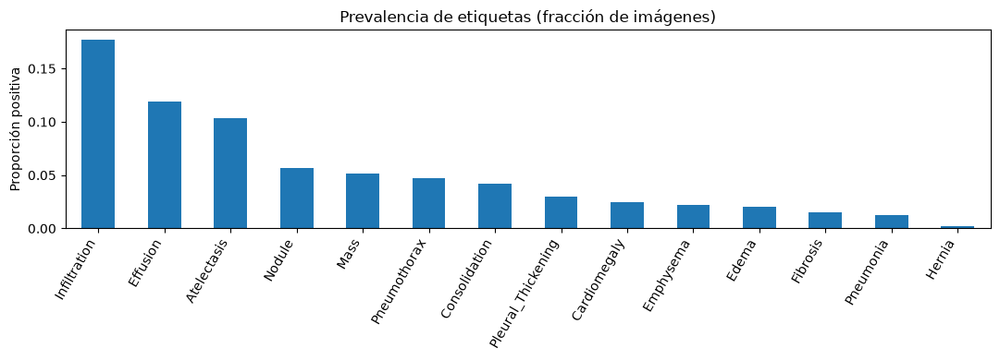

In [ ]:
# Prevalencia por hallazgo en los datos seleccionados.
prevalence = meta[LABELS].mean().sort_values(ascending=False)
prevalence.plot.bar(figsize=(11,4), title='Prevalencia de etiquetas (fracción de imágenes)')
plt.ylabel('Proporción positiva'); plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()


## 4. Dataset y transformaciones

Se redimensiona a 224×224, se normaliza con estadísticas ImageNet y se aplica una rotación pequeña solo al entrenamiento. El `DataLoader` usa `NUM_WORKERS=0` para mayor estabilidad en Mac.


In [5]:
class ChestDataset(Dataset):
    def __init__(self, frame, transform): self.frame=frame.reset_index(drop=True); self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row=self.frame.iloc[idx]
        with Image.open(row.ImagePath) as im: image=im.convert('RGB')
        image=self.transform(image)
        target=torch.tensor(row[LABELS].to_numpy(dtype=np.float32))
        return image,target

train_tf=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)), transforms.RandomRotation(7),
    transforms.ToTensor(), transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
eval_tf=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)), transforms.ToTensor(),
    transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
frames={s:meta[meta.split==s] for s in ['train','val','test']}
datasets={'train':ChestDataset(frames['train'],train_tf), 'val':ChestDataset(frames['val'],eval_tf), 'test':ChestDataset(frames['test'],eval_tf)}
loaders={s:DataLoader(ds,batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type=='cuda')) for s,ds in datasets.items()}


## 5. Modelos y evaluación

Los tres modelos usan pesos ImageNet, una salida de 14 logits y `BCEWithLogitsLoss`. Usamos AdamW con la misma tasa de aprendizaje, tamaño de imagen, split y máximo de épocas. Se elige el checkpoint por macro F1 de validación y se calcula el test una sola vez con ese checkpoint. Accuracy es exactitud de subconjunto (todas las etiquetas de una imagen deben coincidir); por el desbalance, se interpreta junto con F1 y AUROC.


In [6]:
def create_model(name):
    if name=='resnet18':
        m=models.resnet18(weights=models.ResNet18_Weights.DEFAULT); m.fc=nn.Linear(m.fc.in_features,len(LABELS))
    elif name=='densenet121':
        m=models.densenet121(weights=models.DenseNet121_Weights.DEFAULT); m.classifier=nn.Linear(m.classifier.in_features,len(LABELS))
    elif name=='efficientnet_b0':
        m=models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT); m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,len(LABELS))
    else: raise ValueError(name)
    return m

@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval(); ys=[]; probs=[]; losses=[]; start=time.perf_counter()
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x); losses.append(criterion(logits,y).item())
        ys.append(y.cpu().numpy()); probs.append(torch.sigmoid(logits).cpu().numpy())
    y=np.concatenate(ys); p=np.concatenate(probs); pred=(p>=.5).astype(np.uint8)
    try: auc=float(roc_auc_score(y,p,average='macro'))
    except ValueError: auc=float('nan')
    return {'loss':float(np.mean(losses)), 'accuracy_exact':float(accuracy_score(y,pred)),
            'f1_macro':float(f1_score(y,pred,average='macro',zero_division=0)),
            'f1_micro':float(f1_score(y,pred,average='micro',zero_division=0)),
            'auroc_macro':auc, 'eval_seconds':time.perf_counter()-start}


In [7]:
def train_model(name):
    model=create_model(name).to(DEVICE)
    params=sum(p.numel() for p in model.parameters())
    criterion=nn.BCEWithLogitsLoss()
    optimizer=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
    best_f1=-1; best_epoch=0; history=[]; ckpt=OUTPUT_DIR/f'{name}_best.pt'
    for epoch in range(1,EPOCHS+1):
        model.train(); start=time.perf_counter(); total=0; seen=0
        for x,y in tqdm(loaders['train'],desc=f'{name} {epoch}/{EPOCHS}'):
            x,y=x.to(DEVICE),y.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(x),y); loss.backward(); optimizer.step()
            total += loss.item()*len(x); seen += len(x)
        train_seconds=time.perf_counter()-start
        val=evaluate(model,loaders['val'],criterion)
        row={'model':name,'epoch':epoch,'train_loss':total/seen,'train_seconds':train_seconds,
             **{f'val_{k}':v for k,v in val.items()}}
        history.append(row); print(row)
        if val['f1_macro']>best_f1:
            best_f1=val['f1_macro']; best_epoch=epoch
            torch.save({'state_dict':model.state_dict(),'epoch':epoch,'labels':LABELS},ckpt)
    pd.DataFrame(history).to_csv(OUTPUT_DIR/f'{name}_history.csv',index=False)
    checkpoint=torch.load(ckpt,map_location=DEVICE,weights_only=False)
    model.load_state_dict(checkpoint['state_dict'])
    test=evaluate(model,loaders['test'],criterion)
    del model
    if DEVICE.type=='mps': torch.mps.empty_cache()
    return {'model':name,'parameters':params,'best_epoch':best_epoch,'best_val_f1_macro':best_f1,
            **{f'test_{k}':v for k,v in test.items()}}


## 6. Entrenamiento y resultados

La primera ejecución descarga los pesos preentrenados de torchvision. Un piloto con `MAX_IMAGES=1000`, un modelo y una época sirve para comprobar el flujo; no se debe presentar como resultado final.


In [8]:
# Para una prueba rápida, cambia arriba: MAX_IMAGES=1000, EPOCHS=1,
# MODELS_TO_RUN=['resnet18']. Luego reinicia y ejecuta todas las celdas.
config={'seed':SEED,'image_size':IMAGE_SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,
        'max_images':MAX_IMAGES,'models':MODELS_TO_RUN,'device':str(DEVICE)}
(OUTPUT_DIR/'run_config.json').write_text(json.dumps(config,indent=2))
results=[]
for model_name in MODELS_TO_RUN:
    print('Entrenando',model_name)
    results.append(train_model(model_name))
results_df=pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR/'results.csv',index=False)
results_df


Entrenando resnet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/jonathanzapata/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 20.8MB/s]


resnet18 1/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'resnet18', 'epoch': 1, 'train_loss': 0.14611792394447537, 'train_seconds': 1691.0604905839937, 'val_loss': 0.14261489229468338, 'val_accuracy_exact': 0.575218818380744, 'val_f1_macro': 0.08118642723234208, 'val_f1_micro': 0.143664047151277, 'val_auroc_macro': 0.7893101907244013, 'val_eval_seconds': 166.44222495899885}


resnet18 2/5:   0%|          | 0/9445 [00:00<?, ?it/s]

...

efficientnet_b0 4/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'efficientnet_b0', 'epoch': 4, 'train_loss': 0.1280338470419515, 'train_seconds': 2908.9551973329944, 'val_loss': 0.1385745569563625, 'val_accuracy_exact': 0.5702954048140044, 'val_f1_macro': 0.1554636835592509, 'val_f1_micro': 0.2546537602382725, 'val_auroc_macro': 0.8193686314383298, 'val_eval_seconds': 199.98252041699016}


efficientnet_b0 5/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'efficientnet_b0', 'epoch': 5, 'train_loss': 0.12495022195186889, 'train_seconds': 2899.705844750002, 'val_loss': 0.13873053808342653, 'val_accuracy_exact': 0.5720277169948942, 'val_f1_macro': 0.1522797439734426, 'val_f1_micro': 0.22070814252205964, 'val_auroc_macro': 0.8163136663570505, 'val_eval_seconds': 201.96748304199718}


,model,parameters,best_epoch,best_val_f1_macro,test_loss,test_accuracy_exact,test_f1_macro,test_f1_micro,test_auroc_macro,test_eval_seconds
0,resnet18,11183694,5,0.147146,0.212906,0.370683,0.162936,0.235858,0.790412,377.888691
1,densenet121,6968206,5,0.157116,0.205559,0.365057,0.187145,0.269783,0.804204,547.345333
2,efficientnet_b0,4025482,4,0.155464,0.209740,0.365995,0.195865,0.279628,0.799419,462.863073


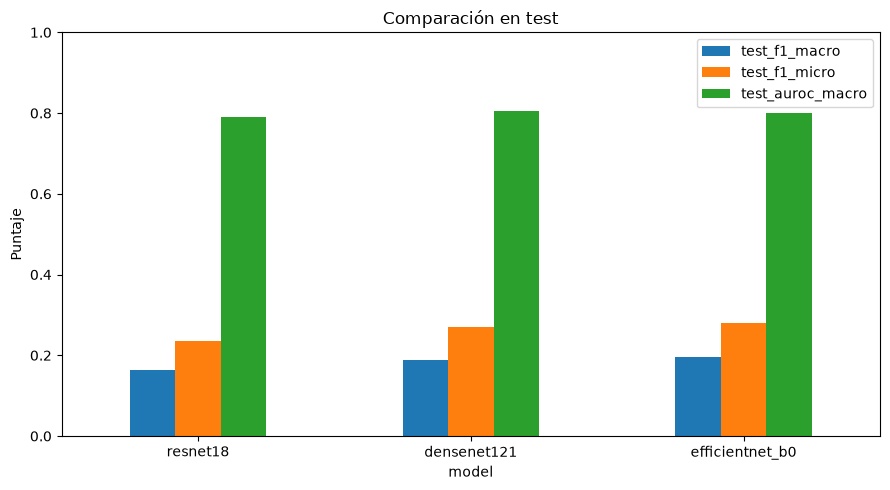

In [9]:
# Gráfica comparativa de métricas de test
metrics=['test_f1_macro','test_f1_micro','test_auroc_macro']
results_df.set_index('model')[metrics].plot.bar(figsize=(9,5),ylim=(0,1),title='Comparación en test')
plt.ylabel('Puntaje'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()


## 7. Lectura crítica y limitaciones

- Reporta el split, semilla, número de épocas, batch, resolución y dispositivo junto con las métricas.
- Los positivos son poco frecuentes en varias etiquetas; el umbral fijo 0.5 puede no ser óptimo. Como extensión, ajusta umbrales usando solo validación.
- Compara costo con parámetros y segundos por época/entrenamiento. El tiempo depende de temperatura, memoria y carga del equipo. Registra también la memoria observada por el sistema si el profesor la solicita.
- NIH usa etiquetas automáticas y existe riesgo de sesgo por paciente, institución y vista. El split agrupado reduce fuga por paciente, pero no demuestra generalización externa.
- Para interpretabilidad, una extensión natural es Grad-CAM por patología y una revisión cualitativa de falsos positivos/negativos. No interpretes los mapas como prueba causal.
- Los pesos ImageNet implican descarga inicial; la primera época también puede incluir costos de inicialización. Para mayor rigor, repite con varias semillas si el presupuesto de cómputo lo permite.

Los outputs quedan en `outputs/`.


## 8. Análisis detallado de la ejecución existente

Las siguientes celdas leen los historiales por época y la tabla de resultados ya guardados en `outputs/`. No entrenan modelos ni escriben archivos. Si vuelves a ejecutar el entrenamiento, vuelve a ejecutar estas celdas para refrescar el análisis.

### Evolución de entrenamiento y validación


### Curvas de entrenamiento


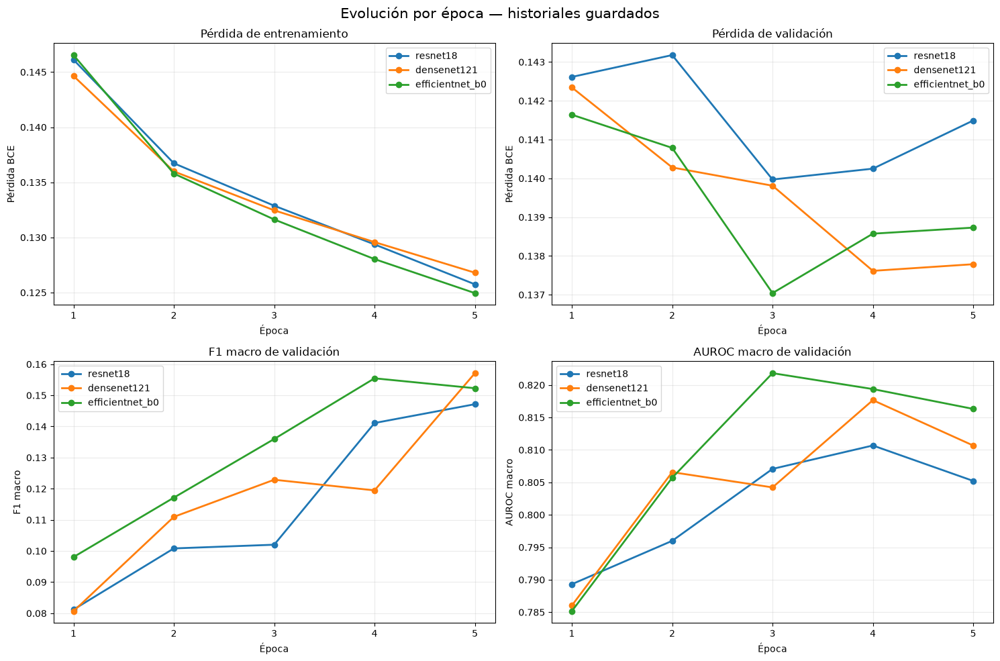

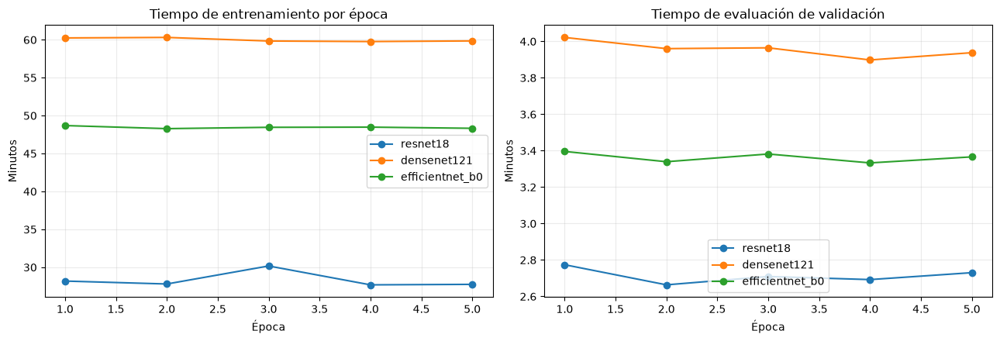

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

analysis_output_dir = Path.cwd() / 'outputs'
analysis_models = ['resnet18', 'densenet121', 'efficientnet_b0']
analysis_histories = {}
for model_name in analysis_models:
    history_path = analysis_output_dir / f'{model_name}_history.csv'
    if history_path.exists():
        analysis_histories[model_name] = pd.read_csv(history_path)
if not analysis_histories:
    raise FileNotFoundError(f'No hay historiales *_history.csv en {analysis_output_dir}')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [
    ('train_loss', 'Pérdida de entrenamiento', 'Pérdida BCE'),
    ('val_loss', 'Pérdida de validación', 'Pérdida BCE'),
    ('val_f1_macro', 'F1 macro de validación', 'F1 macro'),
    ('val_auroc_macro', 'AUROC macro de validación', 'AUROC macro'),
]
for ax, (metric, title, ylabel) in zip(axes.flat, panels):
    for model_name, history in analysis_histories.items():
        if metric in history.columns:
            ax.plot(history['epoch'], history[metric], marker='o', linewidth=2, label=model_name)
    ax.set(title=title, xlabel='Época', ylabel=ylabel)
    ax.set_xticks(sorted({int(e) for h in analysis_histories.values() for e in h['epoch']}))
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle('Evolución por época — historiales guardados', fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_name, history in analysis_histories.items():
    axes[0].plot(history['epoch'], history['train_seconds'] / 60, marker='o', label=model_name)
    if 'val_eval_seconds' in history:
        axes[1].plot(history['epoch'], history['val_eval_seconds'] / 60, marker='o', label=model_name)
axes[0].set(title='Tiempo de entrenamiento por época', xlabel='Época', ylabel='Minutos')
axes[1].set(title='Tiempo de evaluación de validación', xlabel='Época', ylabel='Minutos')
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend()
fig.tight_layout()
plt.show()

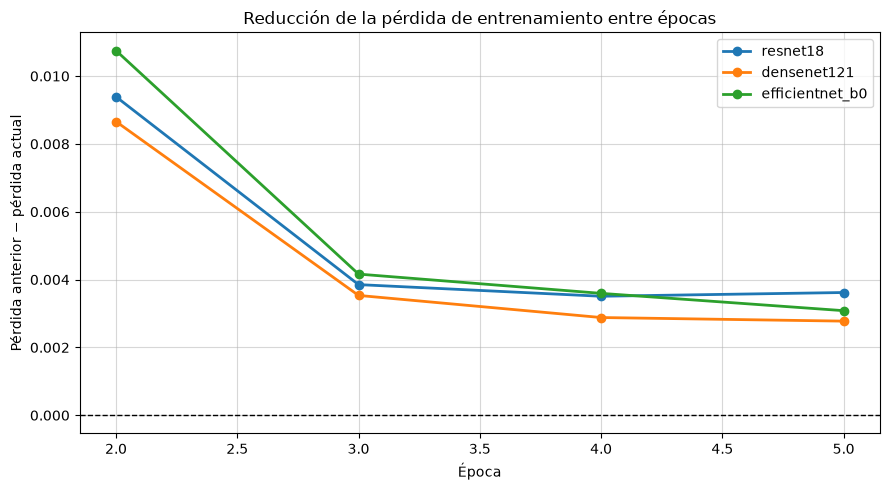

In [26]:
# Descenso observado de la pérdida entre épocas.
# Un valor positivo indica que la pérdida bajó; uno negativo, que subió.
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in analysis_histories.items():
    history = history.sort_values('epoch').copy()
    history['loss_reduction'] = (
        history['train_loss'].shift(1) - history['train_loss']
    )

    ax.plot(
        history['epoch'],
        history['loss_reduction'],
        marker='o',
        linewidth=2,
        label=model_name
    )

ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set(
    title='Reducción de la pérdida de entrenamiento entre épocas',
    xlabel='Época',
    ylabel='Pérdida anterior − pérdida actual'
)
ax.grid(alpha= .5)
ax.legend()
fig.tight_layout()
plt.show()

### Comparación final y resumen automático

El resumen usa `results.csv` (evaluación de test) y los historiales por época. Las métricas se reportan con sus valores observados; el umbral de clasificación es 0.5 y `accuracy_exact` exige acertar todas las etiquetas de una imagen. Los resultados reflejan una sola ejecución y no incluyen intervalos de confianza.


,model,parameters,best_epoch,best_val_f1_macro,test_loss,test_accuracy_exact,test_f1_macro,test_f1_micro,test_auroc_macro,test_eval_seconds
0,efficientnet_b0,"4,025,482",4,0.155,0.210,36.6%,0.196,0.280,0.799,462.9
1,densenet121,"6,968,206",5,0.157,0.206,36.5%,0.187,0.270,0.804,547.3
2,resnet18,"11,183,694",5,0.147,0.213,37.1%,0.163,0.236,0.790,377.9


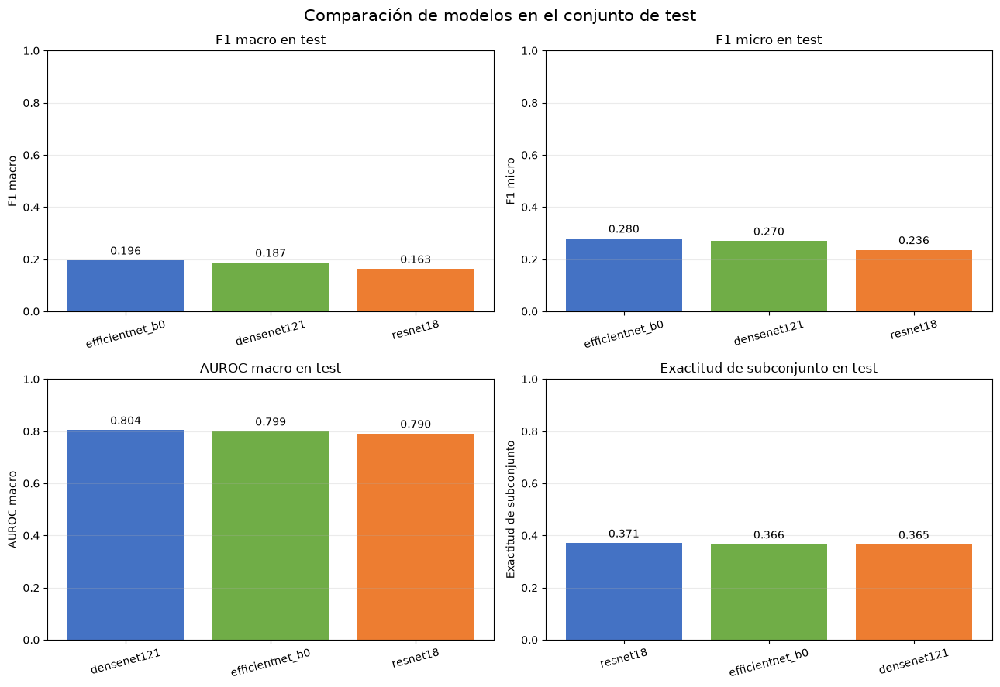

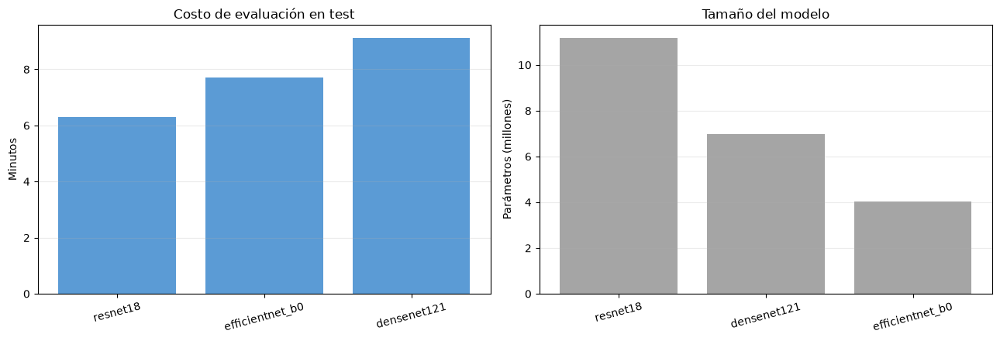

RESUMEN DE ESTA EJECUCIÓN
• Mayor F1 macro de test: efficientnet_b0 (0.196); época elegida por validación: 4.
• Mayor F1 micro de test: efficientnet_b0 (0.280).
• Mayor AUROC macro de test: densenet121 (0.804).
• Evaluación de test más rápida: resnet18 (6.3 min).
• La exactitud es exactitud de subconjunto; dado el desbalance multietiqueta, interprétala junto con F1 y AUROC.
• Los puntajes son modestos y corresponden a una única ejecución con umbral fijo 0.5; no prueban generalización externa.


In [13]:
from IPython.display import display

results_path = analysis_output_dir / 'results.csv'
if not results_path.exists():
    raise FileNotFoundError(f'No se encontró {results_path}')
analysis_results = pd.read_csv(results_path)
display(analysis_results.sort_values('test_f1_macro', ascending=False).reset_index(drop=True).style.format({
    'best_val_f1_macro': '{:.3f}', 'test_loss': '{:.3f}', 'test_accuracy_exact': '{:.1%}',
    'test_f1_macro': '{:.3f}', 'test_f1_micro': '{:.3f}', 'test_auroc_macro': '{:.3f}',
    'test_eval_seconds': '{:.1f}', 'parameters': '{:,.0f}'
}))

plot_specs = [
    ('test_f1_macro', 'F1 macro'), ('test_f1_micro', 'F1 micro'),
    ('test_auroc_macro', 'AUROC macro'), ('test_accuracy_exact', 'Exactitud de subconjunto')
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (metric, label) in zip(axes.flat, plot_specs):
    ordered = analysis_results.sort_values(metric, ascending=False)
    bars = ax.bar(ordered['model'], ordered[metric], color=['#4472C4', '#70AD47', '#ED7D31'][:len(ordered)])
    ax.set(title=f'{label} en test', ylabel=label, ylim=(0, 1))
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=.25)
    ax.bar_label(bars, fmt='%.3f', padding=3)
fig.suptitle('Comparación de modelos en el conjunto de test', fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ordered = analysis_results.sort_values('test_eval_seconds')
axes[0].bar(ordered['model'], ordered['test_eval_seconds'] / 60, color='#5B9BD5')
axes[0].set(title='Costo de evaluación en test', ylabel='Minutos')
axes[1].bar(analysis_results['model'], analysis_results['parameters'] / 1e6, color='#A5A5A5')
axes[1].set(title='Tamaño del modelo', ylabel='Parámetros (millones)')
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()

best_f1 = analysis_results.loc[analysis_results['test_f1_macro'].idxmax()]
best_auc = analysis_results.loc[analysis_results['test_auroc_macro'].idxmax()]
best_micro = analysis_results.loc[analysis_results['test_f1_micro'].idxmax()]
fastest = analysis_results.loc[analysis_results['test_eval_seconds'].idxmin()]
print('RESUMEN DE ESTA EJECUCIÓN')
print(f"• Mayor F1 macro de test: {best_f1['model']} ({best_f1['test_f1_macro']:.3f}); época elegida por validación: {int(best_f1['best_epoch'])}.")
print(f"• Mayor F1 micro de test: {best_micro['model']} ({best_micro['test_f1_micro']:.3f}).")
print(f"• Mayor AUROC macro de test: {best_auc['model']} ({best_auc['test_auroc_macro']:.3f}).")
print(f"• Evaluación de test más rápida: {fastest['model']} ({fastest['test_eval_seconds']/60:.1f} min).")
print('• La exactitud es exactitud de subconjunto; dado el desbalance multietiqueta, interprétala junto con F1 y AUROC.')
print('• Los puntajes son modestos y corresponden a una única ejecución con umbral fijo 0.5; no prueban generalización externa.')

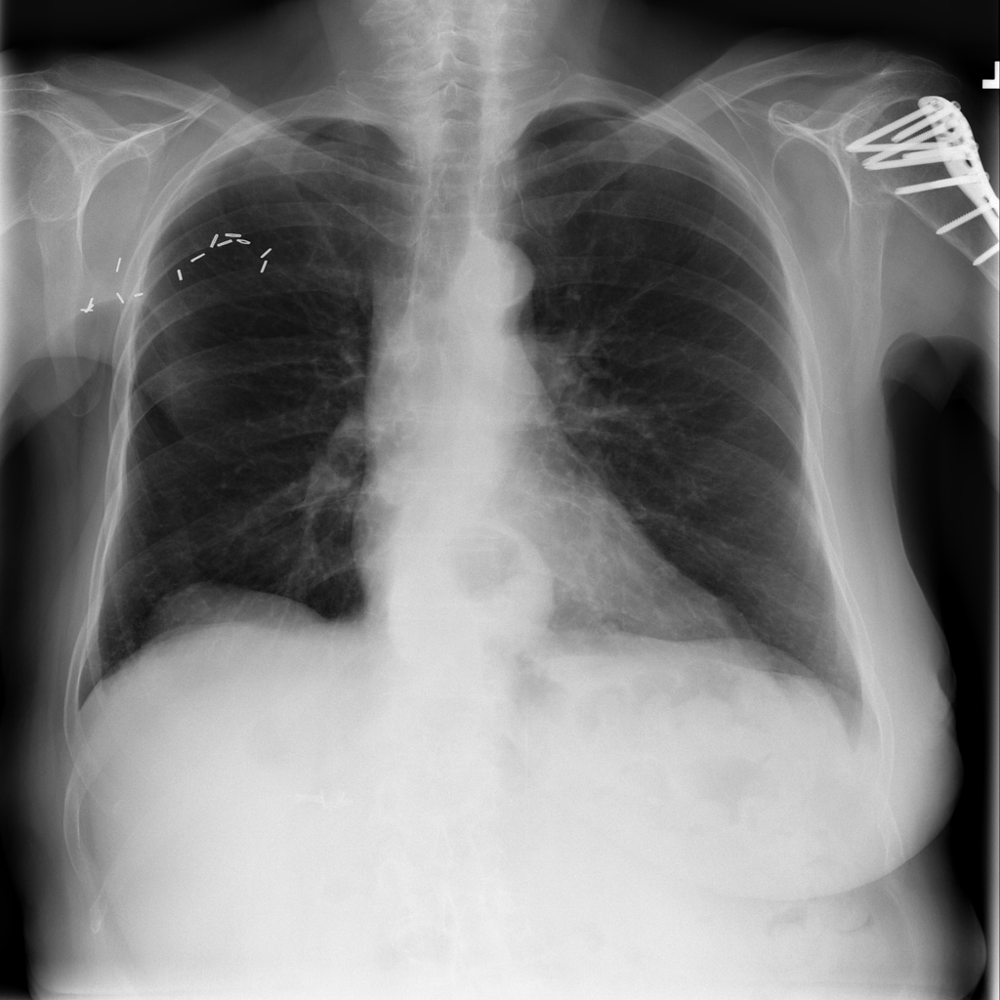

Imagen: 00000003_000.png
Etiquetas reales: ['Hernia']
Predicciones con umbral 0.5: ['Hernia']
Cinco probabilidades más altas:
  Hernia: 0.814
  Infiltration: 0.192
  Nodule: 0.116
  Fibrosis: 0.096
  Mass: 0.080


In [14]:
from pathlib import Path
from IPython.display import display

# Selecciona un registro del conjunto de test.
manifest = pd.read_csv(OUTPUT_DIR / 'split_manifest.csv')
test_rows = manifest[manifest['split'] == 'test'].reset_index(drop=True)
row = test_rows.iloc[0]

# Busca la imagen por ruta registrada; si esa ruta ya no existe, búscala en DATA_ROOT.
image_path = Path(row['ImagePath'])
if not image_path.exists():
    matches = list(DATA_ROOT.rglob(row['Image Index']))
    if not matches:
        raise FileNotFoundError(f"No se encontró {row['Image Index']} dentro de {DATA_ROOT}")
    image_path = matches[0]

# EfficientNet-B0: época 4 fue la elegida por F1 macro de validación.
model_name = 'efficientnet_b0'
checkpoint = torch.load(
    OUTPUT_DIR / f'{model_name}_best.pt',
    map_location=DEVICE,
    weights_only=False
)
model = create_model(model_name).to(DEVICE)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

# La entrada del modelo tiene forma [1, 3, 224, 224].
with Image.open(image_path) as im:
    image = im.convert('RGB')
    display(image)
    x = eval_tf(image).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    probabilities = torch.sigmoid(model(x))[0].cpu().numpy()

# Compara las predicciones con las etiquetas conocidas de esta imagen.
true_labels = [label for label in LABELS if row[label] == 1]
predicted_labels = [label for label, p in zip(LABELS, probabilities) if p >= 0.5]
top_indices = np.argsort(probabilities)[::-1][:5]

print('Imagen:', row['Image Index'])
print('Etiquetas reales:', true_labels or ['No Finding'])
print('Predicciones con umbral 0.5:', predicted_labels or ['ninguna'])
print('Cinco probabilidades más altas:')
for i in top_indices:
    print(f'  {LABELS[i]}: {probabilities[i]:.3f}')

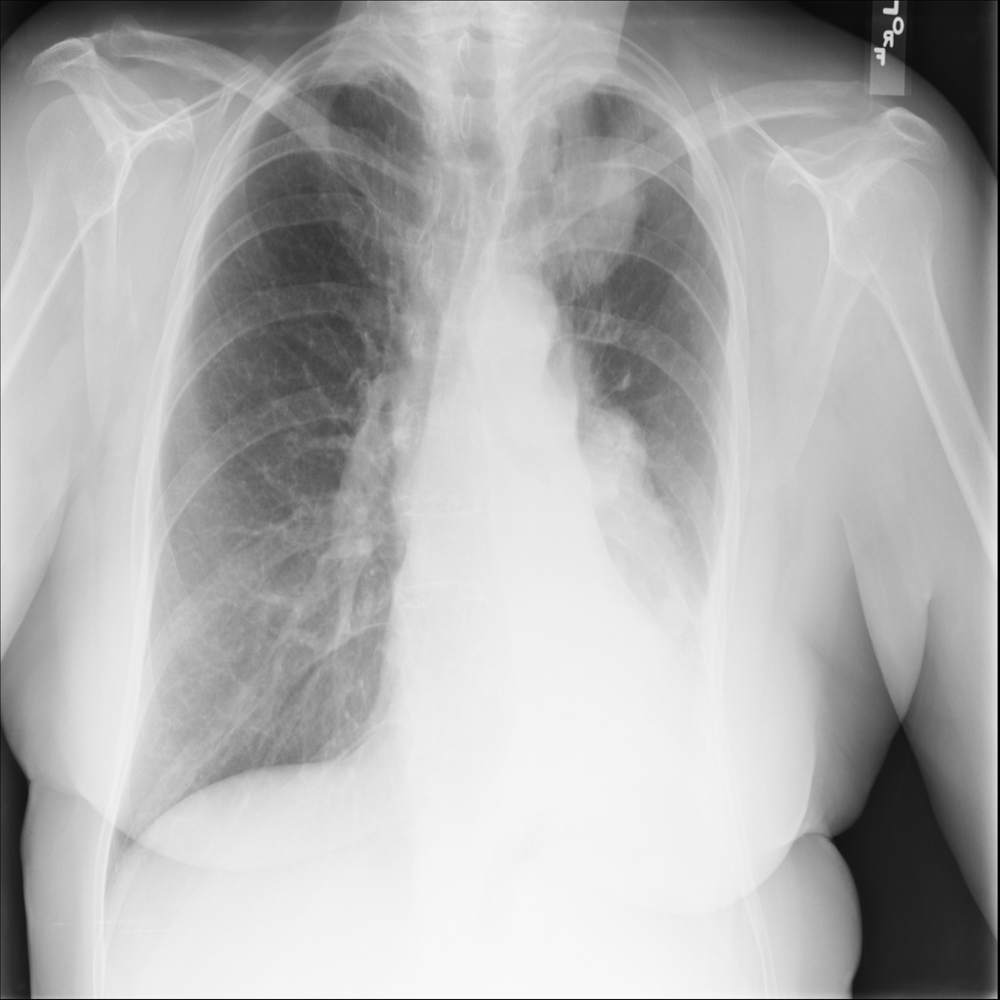

Imagen: 00013659_006.png
Etiquetas reales: ['Atelectasis', 'Mass']
Predicciones con umbral 0.5: ['ninguna']
Cinco probabilidades más altas:
  Effusion: 0.400
  Mass: 0.322
  Consolidation: 0.210
  Atelectasis: 0.179
  Infiltration: 0.168



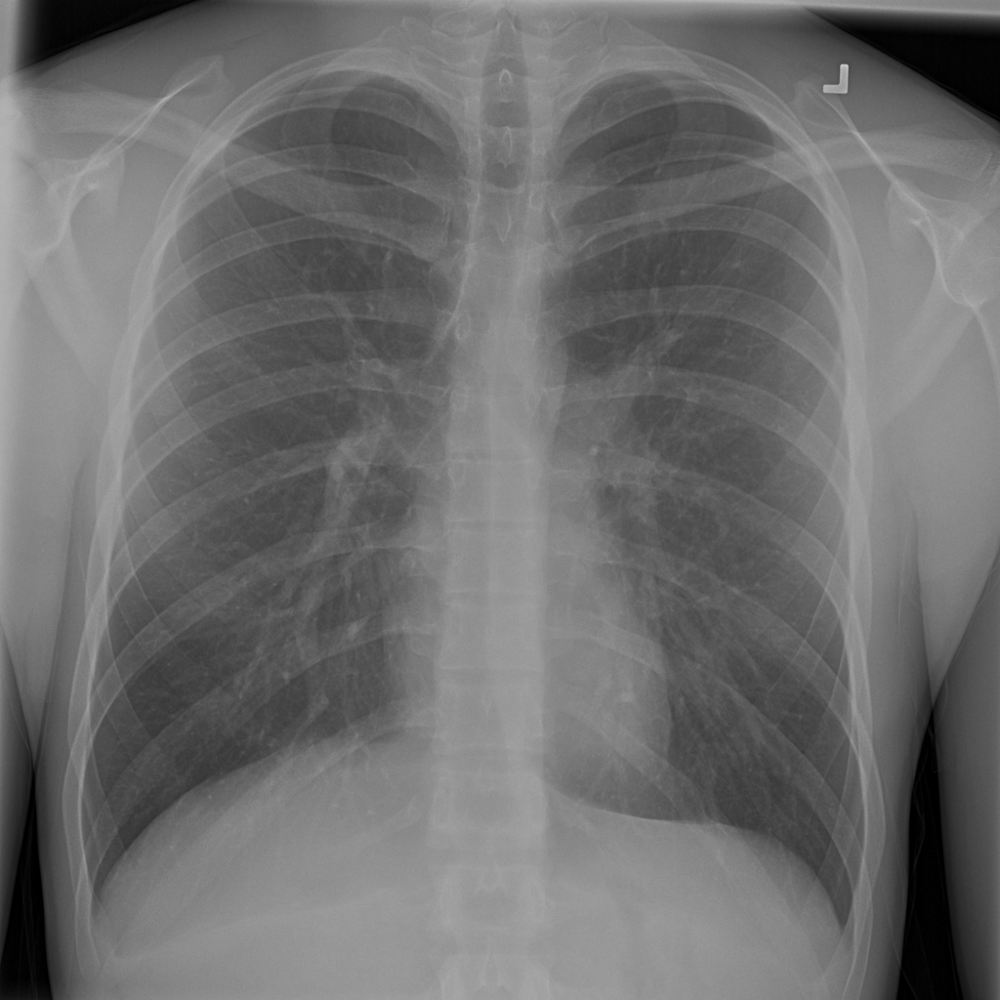

Imagen: 00030445_000.png
Etiquetas reales: ['No Finding']
Predicciones con umbral 0.5: ['ninguna']
Cinco probabilidades más altas:
  Infiltration: 0.164
  Nodule: 0.020
  Effusion: 0.009
  Pleural_Thickening: 0.007
  Mass: 0.006



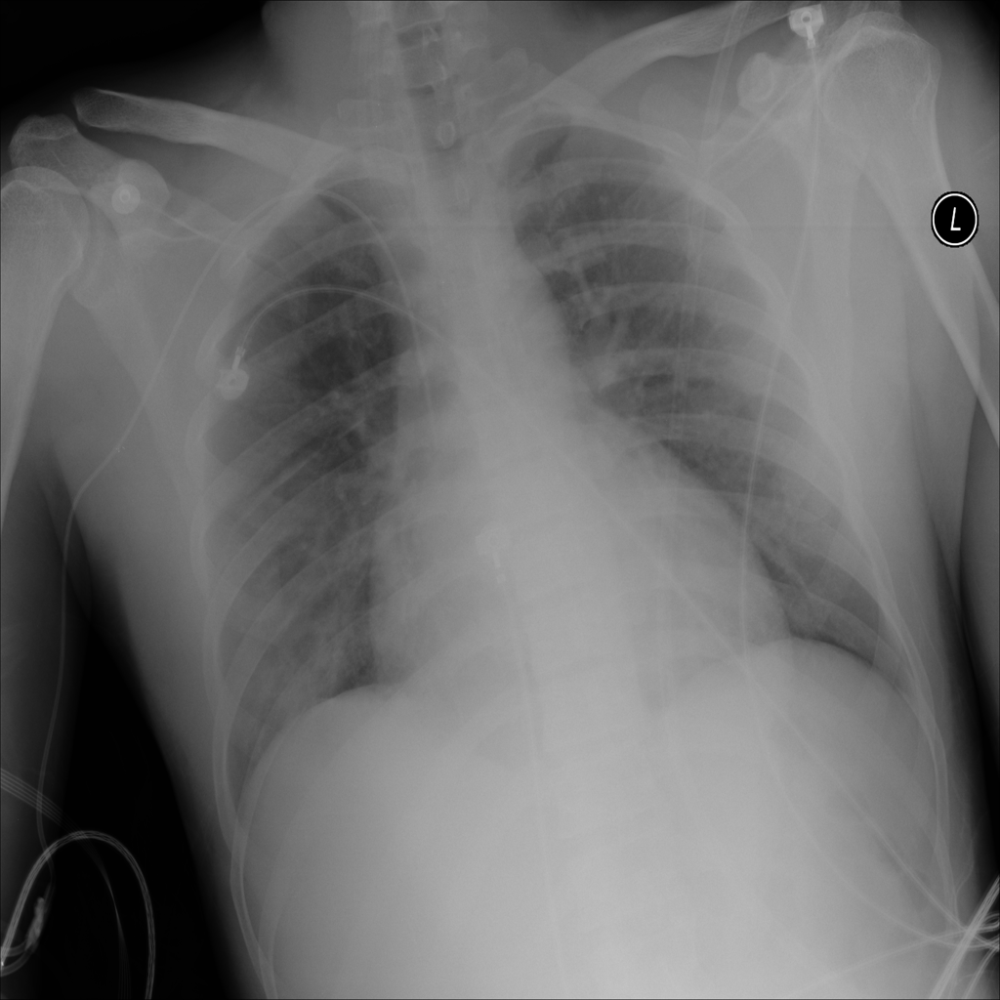

Imagen: 00019018_026.png
Etiquetas reales: ['No Finding']
Predicciones con umbral 0.5: ['ninguna']
Cinco probabilidades más altas:
  Infiltration: 0.099
  Cardiomegaly: 0.095
  Edema: 0.042
  Effusion: 0.032
  Nodule: 0.020



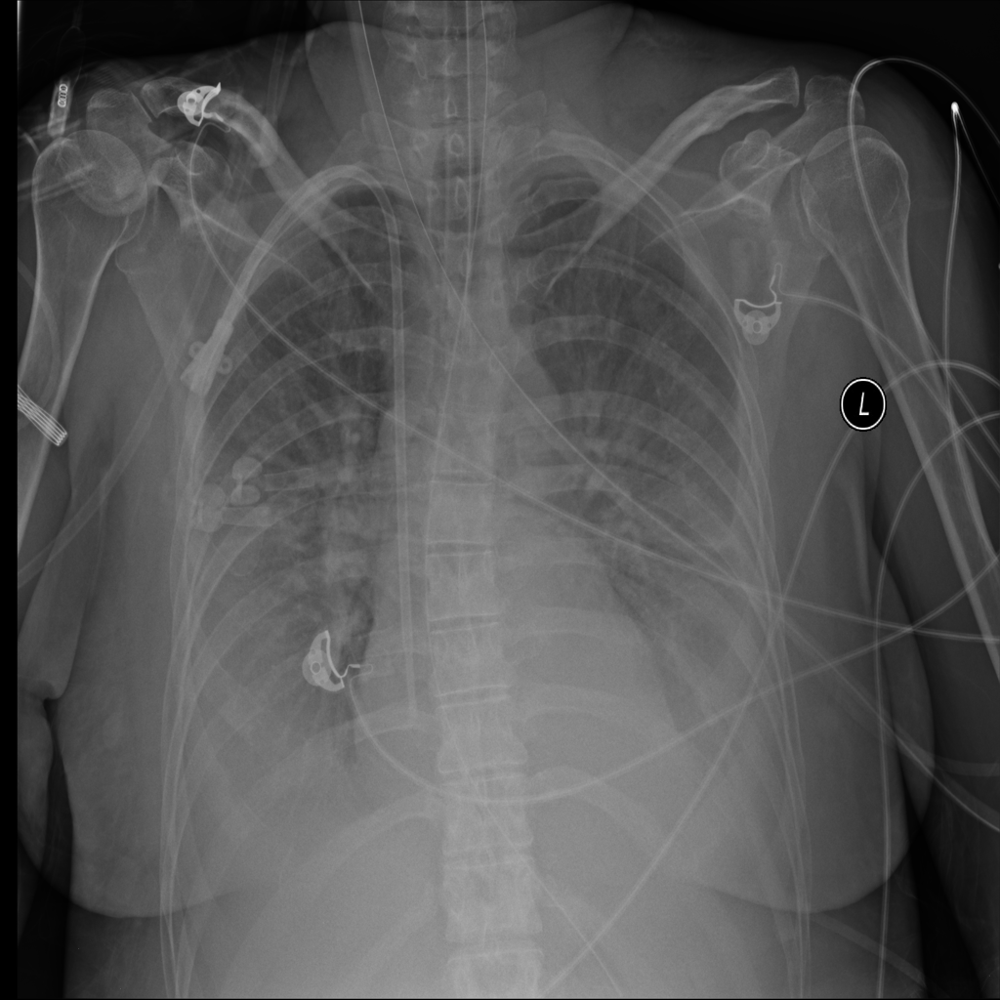

Imagen: 00028518_011.png
Etiquetas reales: ['No Finding']
Predicciones con umbral 0.5: ['Effusion']
Cinco probabilidades más altas:
  Effusion: 0.812
  Infiltration: 0.434
  Consolidation: 0.397
  Atelectasis: 0.328
  Edema: 0.039



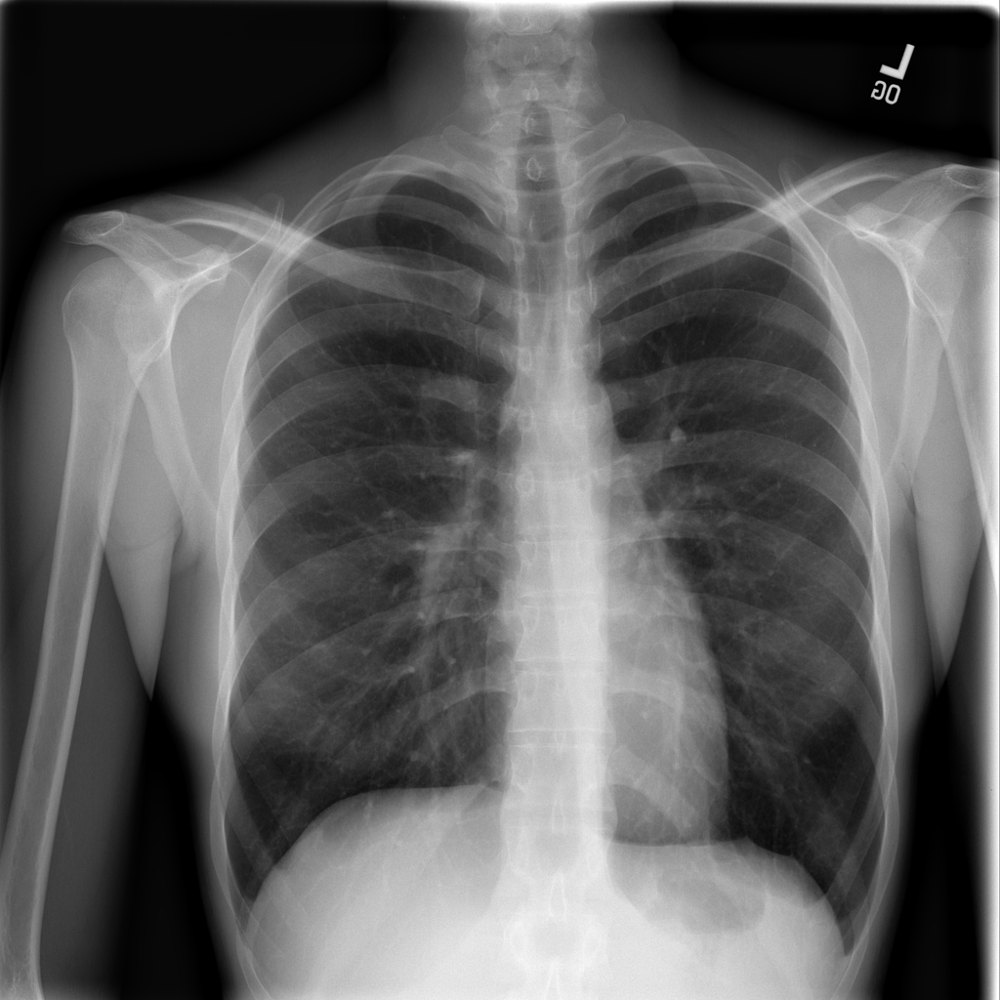

Imagen: 00023026_000.png
Etiquetas reales: ['No Finding']
Predicciones con umbral 0.5: ['ninguna']
Cinco probabilidades más altas:
  Infiltration: 0.300
  Nodule: 0.041
  Pleural_Thickening: 0.007
  Pneumothorax: 0.007
  Mass: 0.006



In [18]:
from pathlib import Path

manifest = pd.read_csv(OUTPUT_DIR / 'split_manifest.csv')
test_rows = manifest[manifest['split'] == 'test'].sample(
    n=5, random_state=42
).reset_index(drop=True)

model_name = 'efficientnet_b0'
checkpoint = torch.load(
    OUTPUT_DIR / f'{model_name}_best.pt',
    map_location=DEVICE,
    weights_only=False
)
model = create_model(model_name).to(DEVICE)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

for _, row in test_rows.iterrows():
    image_name = row['Image Index']
    image_path = Path(row['ImagePath'])

    if not image_path.exists():
        matches = list(DATA_ROOT.rglob(image_name))
        if not matches:
            print(f'No se encontró la imagen: {image_name}\n')
            continue
        image_path = matches[0]

    with Image.open(image_path) as im:
        image = im.convert('RGB')
        display(image)
        x = eval_tf(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        probabilities = torch.sigmoid(model(x))[0].cpu().numpy()

    real_labels = [label for label in LABELS if row[label] == 1]
    predicted_labels = [
        label for label, probability in zip(LABELS, probabilities)
        if probability >= 0.5
    ]
    top_indices = np.argsort(probabilities)[::-1][:5]

    print(f'Imagen: {image_name}')
    print(f'Etiquetas reales: {real_labels or ["No Finding"]}')
    print(f'Predicciones con umbral 0.5: {predicted_labels or ["ninguna"]}')
    print('Cinco probabilidades más altas:')
    for i in top_indices:
        print(f'  {LABELS[i]}: {probabilities[i]:.3f}')
    print()

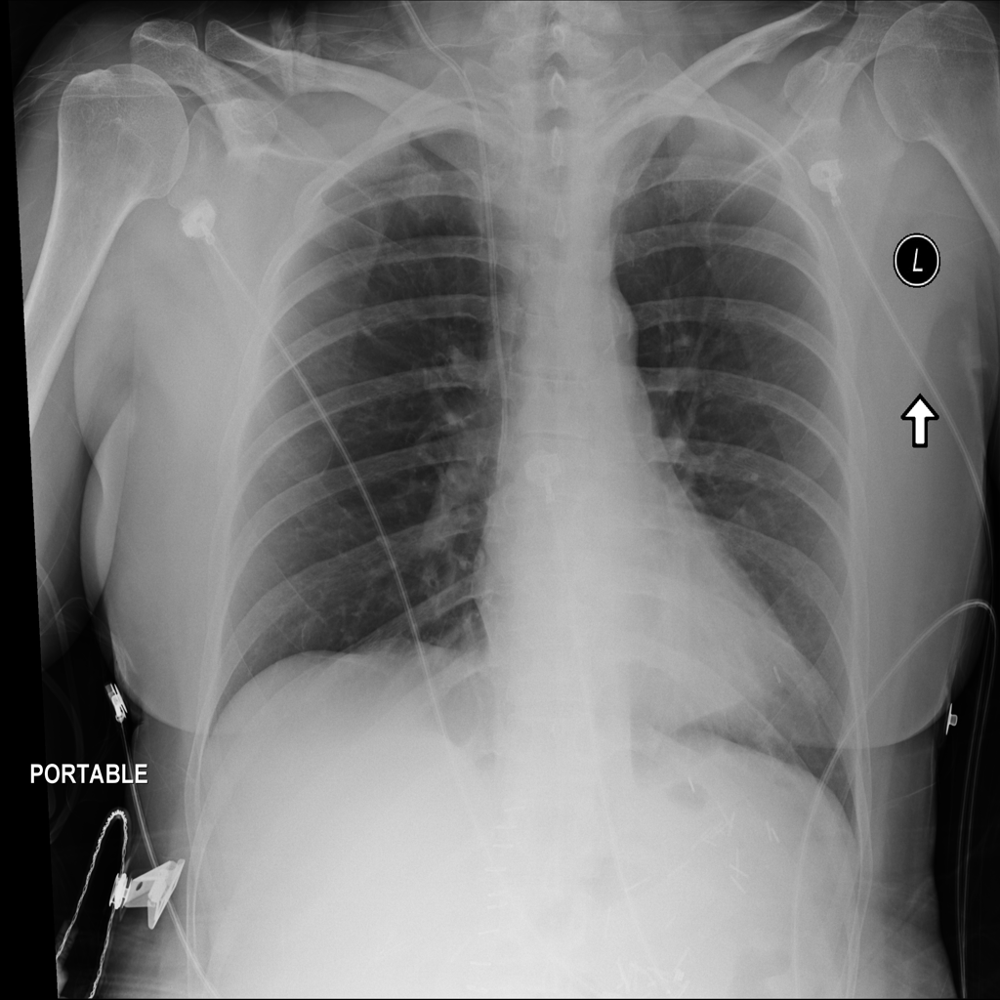

Imagen: 00020259_001.png
Etiquetas reales: ['No Finding']

resnet18:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.073
    Atelectasis: 0.046
    Consolidation: 0.012
    Nodule: 0.011
    Emphysema: 0.008

densenet121:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.089
    Atelectasis: 0.060
    Pneumothorax: 0.052
    Effusion: 0.048
    Nodule: 0.037

efficientnet_b0:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.148
    Atelectasis: 0.112
    Pneumothorax: 0.012
    Nodule: 0.011
    Effusion: 0.009

----------------------------------------------------------------------



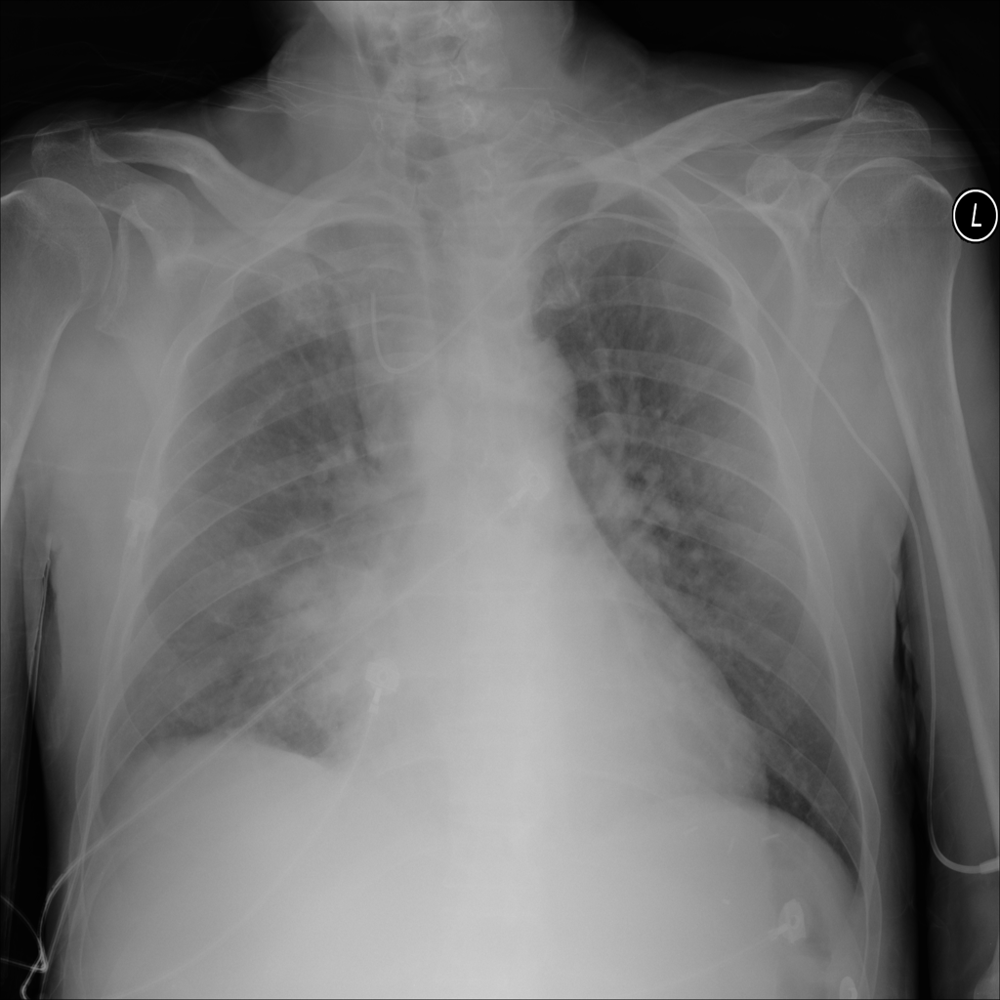

Imagen: 00020725_032.png
Etiquetas reales: ['No Finding']

resnet18:
  Predicciones con umbral 0.5: ['Infiltration']
  Cinco probabilidades más altas:
    Infiltration: 0.518
    Atelectasis: 0.226
    Edema: 0.140
    Effusion: 0.131
    Consolidation: 0.116

densenet121:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.496
    Cardiomegaly: 0.323
    Effusion: 0.297
    Edema: 0.226
    Consolidation: 0.162

efficientnet_b0:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.442
    Mass: 0.199
    Nodule: 0.173
    Consolidation: 0.151
    Effusion: 0.117

----------------------------------------------------------------------



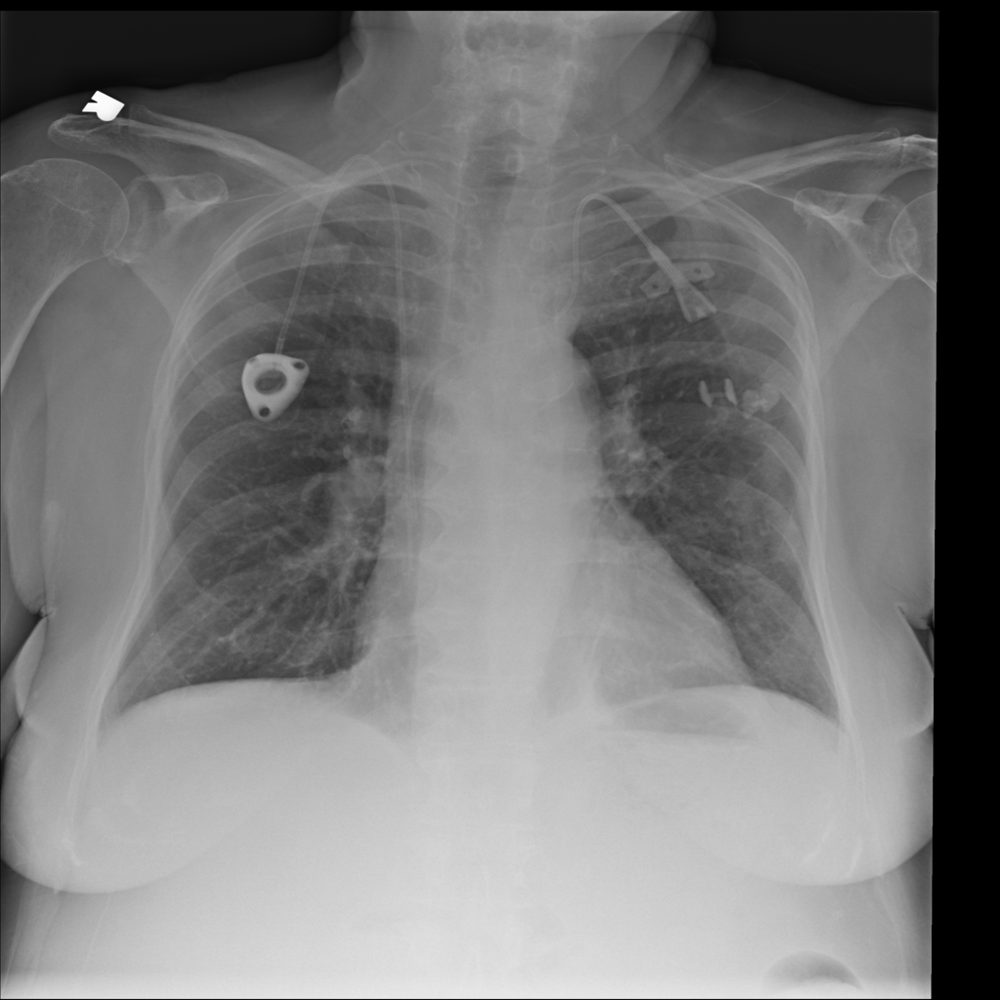

Imagen: 00026474_001.png
Etiquetas reales: ['Atelectasis', 'Infiltration']

resnet18:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Nodule: 0.203
    Mass: 0.117
    Infiltration: 0.117
    Effusion: 0.080
    Pleural_Thickening: 0.052

densenet121:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Effusion: 0.292
    Infiltration: 0.274
    Nodule: 0.082
    Pleural_Thickening: 0.079
    Mass: 0.062

efficientnet_b0:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.260
    Effusion: 0.110
    Atelectasis: 0.070
    Nodule: 0.027
    Consolidation: 0.017

----------------------------------------------------------------------



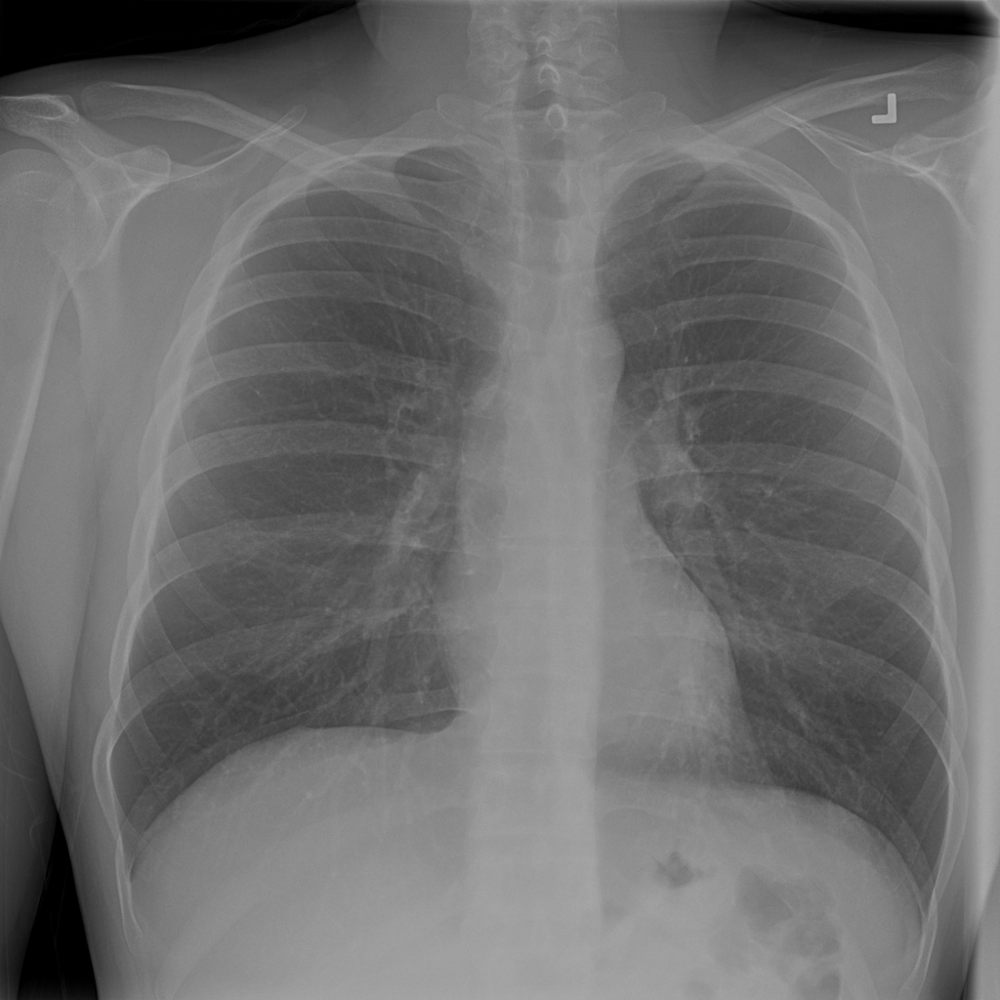

Imagen: 00028246_000.png
Etiquetas reales: ['No Finding']

resnet18:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.270
    Nodule: 0.034
    Atelectasis: 0.031
    Pleural_Thickening: 0.026
    Fibrosis: 0.017

densenet121:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.497
    Pleural_Thickening: 0.015
    Atelectasis: 0.012
    Nodule: 0.012
    Mass: 0.010

efficientnet_b0:
  Predicciones con umbral 0.5: ['ninguna']
  Cinco probabilidades más altas:
    Infiltration: 0.389
    Nodule: 0.008
    Atelectasis: 0.002
    Pneumonia: 0.001
    Pleural_Thickening: 0.001

----------------------------------------------------------------------



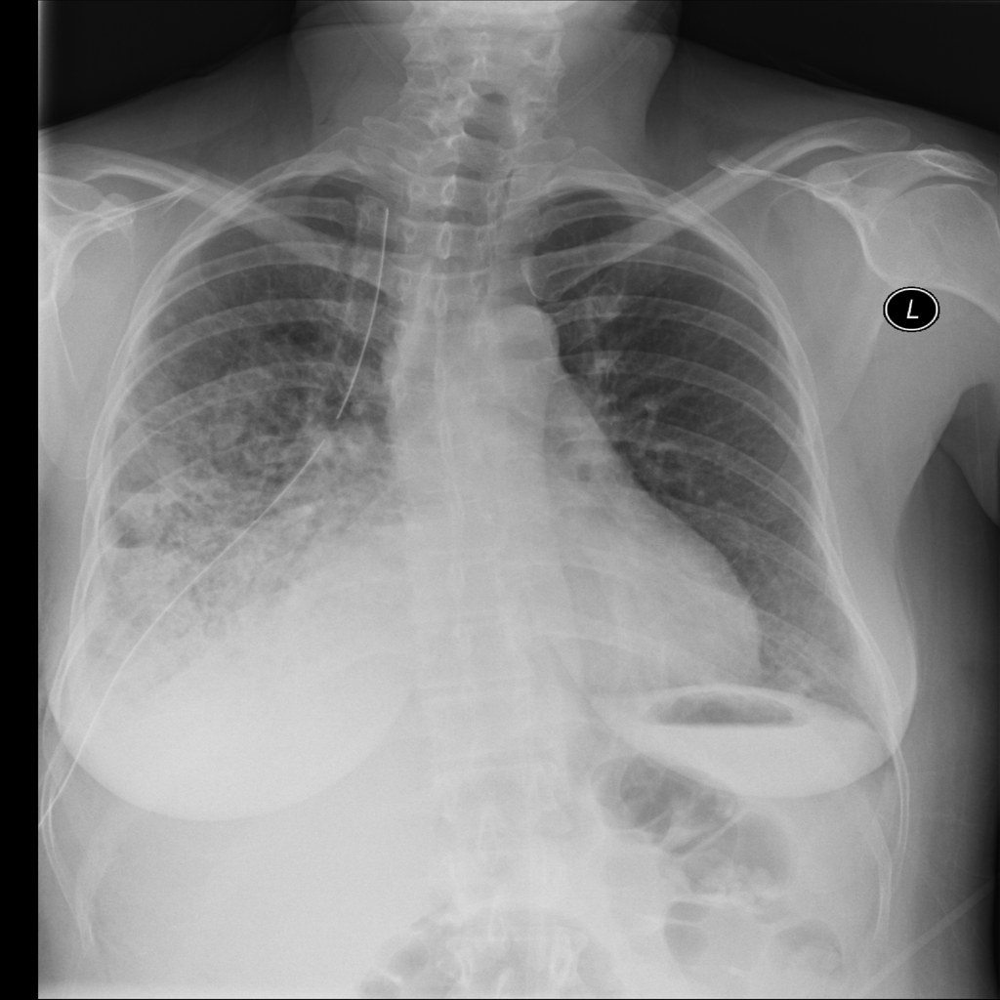

Imagen: 00013391_005.png
Etiquetas reales: ['Infiltration', 'Pneumonia']

resnet18:
  Predicciones con umbral 0.5: ['Effusion']
  Cinco probabilidades más altas:
    Effusion: 0.540
    Infiltration: 0.445
    Cardiomegaly: 0.111
    Pleural_Thickening: 0.111
    Atelectasis: 0.104

densenet121:
  Predicciones con umbral 0.5: ['Effusion']
  Cinco probabilidades más altas:
    Effusion: 0.620
    Infiltration: 0.495
    Cardiomegaly: 0.209
    Consolidation: 0.129
    Pleural_Thickening: 0.113

efficientnet_b0:
  Predicciones con umbral 0.5: ['Effusion', 'Infiltration']
  Cinco probabilidades más altas:
    Effusion: 0.664
    Infiltration: 0.616
    Atelectasis: 0.103
    Pleural_Thickening: 0.087
    Nodule: 0.076

----------------------------------------------------------------------



In [20]:
# Excluye las cinco imágenes de la comparación anterior.
previous_rows = manifest[manifest['split'] == 'test'].sample(
    n=5, random_state=42
)
previous_names = set(previous_rows['Image Index'])

remaining_rows = manifest[
    (manifest['split'] == 'test') &
    (~manifest['Image Index'].isin(previous_names))
]

test_rows = remaining_rows.sample(n=5, random_state=123).reset_index(drop=True)

for _, row in test_rows.iterrows():
    image_name = row['Image Index']
    image_path = Path(row['ImagePath'])

    if not image_path.exists():
        matches = list(DATA_ROOT.rglob(image_name))
        if not matches:
            print(f'No se encontró la imagen: {image_name}\n')
            continue
        image_path = matches[0]

    with Image.open(image_path) as im:
        image = im.convert('RGB')
        display(image)
        x = eval_tf(image).unsqueeze(0).to(DEVICE)

    real_labels = [label for label in LABELS if row[label] == 1]

    print(f'Imagen: {image_name}')
    print(f'Etiquetas reales: {real_labels or ["No Finding"]}')

    for model_name, model in models_loaded.items():
        with torch.inference_mode():
            probabilities = torch.sigmoid(model(x))[0].cpu().numpy()

        predicted_labels = [
            label for label, probability in zip(LABELS, probabilities)
            if probability >= 0.5
        ]
        top_indices = np.argsort(probabilities)[::-1][:5]

        print(f'\n{model_name}:')
        print(f'  Predicciones con umbral 0.5: {predicted_labels or ["ninguna"]}')
        print('  Cinco probabilidades más altas:')
        for i in top_indices:
            print(f'    {LABELS[i]}: {probabilities[i]:.3f}')

    print('\n' + '-' * 70 + '\n')

## 9. Desbalance y métricas por patología

Esta sección resume el desbalance usando solo el split de entrenamiento y calcula precisión, recall, F1 y AUROC por patología sobre test con los checkpoints guardados. No entrena ni guarda resultados. La evaluación completa de test tarda varios minutos por modelo; no uses las métricas de test para ajustar umbrales o seleccionar modelos.


,positivos_train,negativos_train,prevalencia_train,razon_negativo_positivo
Hernia,123,75433,0.16%,613.3:1
Pneumonia,758,74798,1.00%,98.7:1
Fibrosis,1105,74451,1.46%,67.4:1
Edema,1204,74352,1.59%,61.8:1
Emphysema,1267,74289,1.68%,58.6:1
Cardiomegaly,1498,74058,1.98%,49.4:1
Pleural_Thickening,1973,73583,2.61%,37.3:1
Pneumothorax,2254,73302,2.98%,32.5:1
Consolidation,2489,73067,3.29%,29.4:1
Mass,3499,72057,4.63%,20.6:1


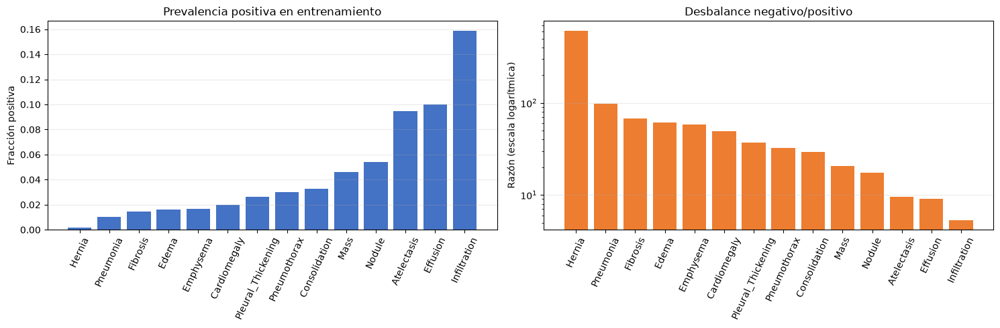

,model,patologia,support_test,precision,recall_sensibilidad,f1,auroc
14,densenet121,Atelectasis,3279,0.517,0.088,0.151,0.768
28,efficientnet_b0,Atelectasis,3279,0.498,0.145,0.224,0.765
0,resnet18,Atelectasis,3279,0.483,0.097,0.162,0.748
15,densenet121,Cardiomegaly,1069,0.545,0.238,0.331,0.883
29,efficientnet_b0,Cardiomegaly,1069,0.557,0.160,0.249,0.869
1,resnet18,Cardiomegaly,1069,0.522,0.136,0.215,0.865
22,densenet121,Consolidation,1815,0.200,0.001,0.002,0.744
36,efficientnet_b0,Consolidation,1815,0.220,0.006,0.012,0.738
8,resnet18,Consolidation,1815,0.000,0.000,0.000,0.738
23,densenet121,Edema,925,0.264,0.030,0.054,0.839


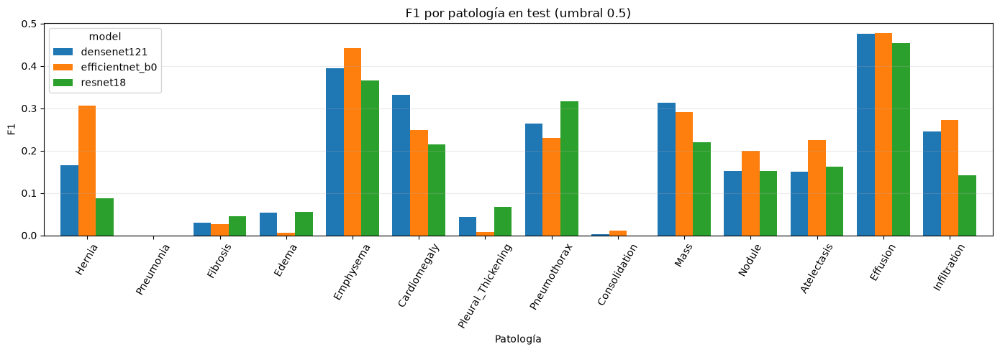

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

diagnostic_manifest = pd.read_csv(OUTPUT_DIR / 'split_manifest.csv')
diagnostic_train = diagnostic_manifest[diagnostic_manifest['split'] == 'train']
positive_counts = diagnostic_train[LABELS].sum().astype(int)
negative_counts = len(diagnostic_train) - positive_counts
imbalance_table = pd.DataFrame({
    'positivos_train': positive_counts,
    'negativos_train': negative_counts,
    'prevalencia_train': positive_counts / len(diagnostic_train),
    'razon_negativo_positivo': negative_counts / positive_counts.replace(0, np.nan),
}).sort_values('prevalencia_train')
display(imbalance_table.style.format({
    'prevalencia_train': '{:.2%}', 'razon_negativo_positivo': '{:.1f}:1'
}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(imbalance_table.index, imbalance_table['prevalencia_train'], color='#4472C4')
axes[0].set(title='Prevalencia positiva en entrenamiento', ylabel='Fracción positiva')
axes[1].bar(imbalance_table.index, imbalance_table['razon_negativo_positivo'], color='#ED7D31')
axes[1].set(title='Desbalance negativo/positivo', ylabel='Razón (escala logarítmica)')
axes[1].set_yscale('log')
for ax in axes:
    ax.tick_params(axis='x', rotation=65)
    ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()

diagnostic_class_rows = []
for model_name in ['resnet18', 'densenet121', 'efficientnet_b0']:
    checkpoint = torch.load(
        OUTPUT_DIR / f'{model_name}_best.pt', map_location=DEVICE, weights_only=False
    )
    diagnostic_model = create_model(model_name).to(DEVICE)
    diagnostic_model.load_state_dict(checkpoint['state_dict'])
    diagnostic_model.eval()
    true_batches, probability_batches = [], []
    with torch.inference_mode():
        for x_batch, y_batch in loaders['test']:
            logits = diagnostic_model(x_batch.to(DEVICE))
            true_batches.append(y_batch.numpy())
            probability_batches.append(torch.sigmoid(logits).cpu().numpy())
    y_true = np.concatenate(true_batches).astype(np.uint8)
    y_score = np.concatenate(probability_batches)
    y_pred = (y_score >= 0.5).astype(np.uint8)
    precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    for j, label in enumerate(LABELS):
        try:
            auc = roc_auc_score(y_true[:, j], y_score[:, j])
        except ValueError:
            auc = np.nan
        diagnostic_class_rows.append({
            'model': model_name, 'patologia': label,
            'support_test': int(y_true[:, j].sum()),
            'precision': precision[j], 'recall_sensibilidad': recall[j],
            'f1': f1[j], 'auroc': auc,
        })
    del diagnostic_model
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()

per_class_results = pd.DataFrame(diagnostic_class_rows)
display(per_class_results.sort_values(['patologia', 'model']).style.format({
    'precision': '{:.3f}', 'recall_sensibilidad': '{:.3f}', 'f1': '{:.3f}', 'auroc': '{:.3f}'
}))

f1_by_class = per_class_results.pivot(index='patologia', columns='model', values='f1')
f1_by_class = f1_by_class.loc[imbalance_table.index]
ax = f1_by_class.plot(kind='bar', figsize=(14, 5), width=.8)
ax.set(title='F1 por patología en test (umbral 0.5)', xlabel='Patología', ylabel='F1')
ax.tick_params(axis='x', rotation=60)
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

## 10. Lectura de convergencia

El experimento guardó cinco puntos por modelo y no definió un criterio formal de parada. Esta tabla ayuda a describir la tendencia observada; no basta para afirmar convergencia si el mejor F1 ocurre en la última época.


In [28]:
convergence_rows = []
for model_name, history in analysis_histories.items():
    history = history.sort_values('epoch').reset_index(drop=True)
    best_idx = history['val_f1_macro'].idxmax()
    best_row = history.loc[best_idx]
    last_row = history.iloc[-1]
    first_loss = history.iloc[0]['train_loss']
    last_loss = last_row['train_loss']
    convergence_rows.append({
        'modelo': model_name,
        'epocas_ejecutadas': int(history['epoch'].max()),
        'epoca_mejor_f1_validacion': int(best_row['epoch']),
        'mejor_f1_macro_validacion': best_row['val_f1_macro'],
        'f1_macro_validacion_ultima_epoca': last_row['val_f1_macro'],
        'reduccion_perdida_train_pct': 100 * (first_loss - last_loss) / first_loss,
        'mejor_f1_en_ultima_epoca': bool(best_row['epoch'] == last_row['epoch']),
    })
convergence_summary = pd.DataFrame(convergence_rows)
display(convergence_summary.style.format({
    'mejor_f1_macro_validacion': '{:.3f}',
    'f1_macro_validacion_ultima_epoca': '{:.3f}',
    'reduccion_perdida_train_pct': '{:.1f}%'
}))
print('Interpretación: si el mejor F1 aparece en la última época, el historial no demuestra que el modelo haya alcanzado una meseta.')

,modelo,epocas_ejecutadas,epoca_mejor_f1_validacion,mejor_f1_macro_validacion,f1_macro_validacion_ultima_epoca,reduccion_perdida_train_pct,mejor_f1_en_ultima_epoca
0,resnet18,5,5,0.147,0.147,13.9%,True
1,densenet121,5,5,0.157,0.157,12.3%,True
2,efficientnet_b0,5,4,0.155,0.152,14.7%,False


Interpretación: si el mejor F1 aparece en la última época, el historial no demuestra que el modelo haya alcanzado una meseta.


## 11. Interpretabilidad exploratoria con Grad-CAM

Genera mapas para una radiografía de test que tenga la patología elegida. Usa los checkpoints guardados y no actualiza pesos. Las zonas resaltadas son una visualización exploratoria de la contribución espacial al logit de esa clase; no son una explicación causal ni una herramienta diagnóstica.


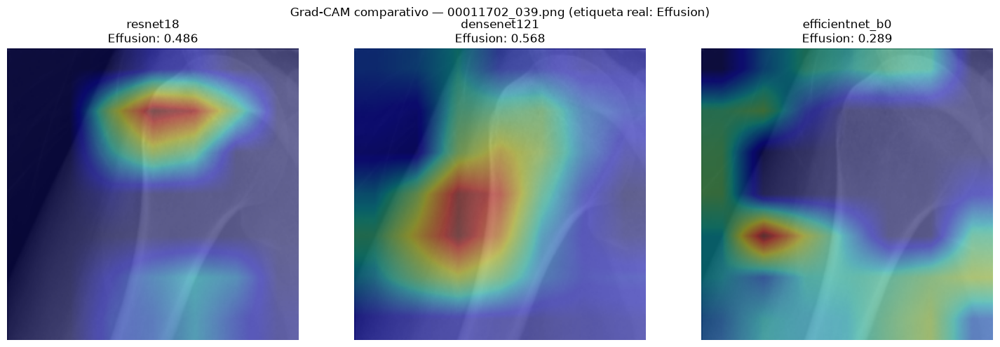

In [29]:
import torch.nn.functional as F

target_label = 'Effusion'  # Cambia por una etiqueta presente en LABELS.
if target_label not in LABELS:
    raise ValueError(f'{target_label} no pertenece a LABELS')
cam_candidates = diagnostic_manifest[
    (diagnostic_manifest['split'] == 'test') &
    (diagnostic_manifest[target_label] == 1)
].sample(n=1, random_state=42)
cam_row = cam_candidates.iloc[0]
cam_image_path = Path(cam_row['ImagePath'])
if not cam_image_path.exists():
    matches = list(DATA_ROOT.rglob(cam_row['Image Index']))
    if not matches:
        raise FileNotFoundError(f"No se encontró {cam_row['Image Index']}")
    cam_image_path = matches[0]
with Image.open(cam_image_path) as im:
    cam_image = im.convert('RGB')
    cam_input = eval_tf(cam_image).unsqueeze(0).to(DEVICE)

cam_layers = {
    'resnet18': lambda m: m.layer4[-1],
    'densenet121': lambda m: m.features.denseblock4,
    'efficientnet_b0': lambda m: m.features[-1],
}
target_index = LABELS.index(target_label)
cam_maps, cam_probabilities = {}, {}
for model_name, get_layer in cam_layers.items():
    checkpoint = torch.load(
        OUTPUT_DIR / f'{model_name}_best.pt', map_location=DEVICE, weights_only=False
    )
    cam_model = create_model(model_name).to(DEVICE)
    cam_model.load_state_dict(checkpoint['state_dict'])
    cam_model.eval()
    captured = {}
    def capture_activation(module, inputs, output):
        captured['activation'] = output
        output.retain_grad()
    hook = get_layer(cam_model).register_forward_hook(capture_activation)
    cam_model.zero_grad(set_to_none=True)
    logits = cam_model(cam_input)
    cam_probabilities[model_name] = torch.sigmoid(logits[0, target_index]).item()
    logits[0, target_index].backward()
    activation = captured['activation']
    gradients = activation.grad
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=cam_input.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam_maps[model_name] = cam.detach().cpu().numpy()
    hook.remove()
    del cam_model
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, model_name in zip(axes, cam_layers):
    ax.imshow(cam_image)
    ax.imshow(cam_maps[model_name], cmap='jet', alpha=.38)
    ax.set_title(f"{model_name}\n{target_label}: {cam_probabilities[model_name]:.3f}")
    ax.axis('off')
fig.suptitle(f"Grad-CAM comparativo — {cam_row['Image Index']} (etiqueta real: {target_label})")
fig.tight_layout()
plt.show()

## 12. Ajuste de umbrales con validación y comparación final en test

El umbral se elige por patología maximizando F1 en validación; en empates se usa el umbral más alto. Después se congela y se mide en test. Así se puede comparar con el umbral fijo 0.5 sin volver a entrenar. Esta celda solo hace inferencia y muestra resultados; no guarda ni sobrescribe archivos. La evaluación completa de validación y test para los tres modelos puede tardar varios minutos.


In [32]:
from sklearn.metrics import precision_recall_curve, f1_score, accuracy_score

def probabilities_for_loader(model, loader):
    ys, probs = [], []
    with torch.inference_mode():
        for x_batch, y_batch in loader:
            logits = model(x_batch.to(DEVICE))
            ys.append(y_batch.numpy())
            probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(ys).astype(np.uint8), np.concatenate(probs)

threshold_rows = []
threshold_test_rows = []
for threshold_model_name in ['resnet18', 'densenet121', 'efficientnet_b0']:
    threshold_checkpoint = torch.load(
        OUTPUT_DIR / f'{threshold_model_name}_best.pt',
        map_location=DEVICE,
        weights_only=False
    )
    threshold_model = create_model(threshold_model_name).to(DEVICE)
    threshold_model.load_state_dict(threshold_checkpoint['state_dict'])
    threshold_model.eval()

    y_val_true, y_val_score = probabilities_for_loader(threshold_model, loaders['val'])
    y_test_true, y_test_score = probabilities_for_loader(threshold_model, loaders['test'])

    selected_thresholds = np.full(len(LABELS), 0.5, dtype=float)
    for j, label in enumerate(LABELS):
        if np.unique(y_val_true[:, j]).size < 2:
            best_val_f1 = f1_score(y_val_true[:, j], y_val_score[:, j] >= 0.5, zero_division=0)
        else:
            precision, recall, candidates = precision_recall_curve(y_val_true[:, j], y_val_score[:, j])
            candidate_f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
            best_value = np.nanmax(candidate_f1)
            best_indices = np.flatnonzero(np.isclose(candidate_f1, best_value))
            best_index = best_indices[-1]  # Desempate determinista: preferir umbral mayor.
            selected_thresholds[j] = candidates[best_index]
            best_val_f1 = candidate_f1[best_index]
        threshold_rows.append({
            'modelo': threshold_model_name,
            'patologia': label,
            'umbral_validacion': selected_thresholds[j],
            'F1_validacion_con_umbral': best_val_f1,
            'positivos_validacion': int(y_val_true[:, j].sum()),
        })

    y_test_pred_05 = (y_test_score >= 0.5).astype(np.uint8)
    y_test_pred_tuned = (y_test_score >= selected_thresholds[None, :]).astype(np.uint8)
    threshold_test_rows.append({
        'modelo': threshold_model_name,
        'F1_macro_test_umbral_0.5': f1_score(y_test_true, y_test_pred_05, average='macro', zero_division=0),
        'F1_macro_test_umbral_validacion': f1_score(y_test_true, y_test_pred_tuned, average='macro', zero_division=0),
        'F1_micro_test_umbral_0.5': f1_score(y_test_true, y_test_pred_05, average='micro', zero_division=0),
        'F1_micro_test_umbral_validacion': f1_score(y_test_true, y_test_pred_tuned, average='micro', zero_division=0),
        'exactitud_test_umbral_0.5': accuracy_score(y_test_true, y_test_pred_05),
        'exactitud_test_umbral_validacion': accuracy_score(y_test_true, y_test_pred_tuned),
    })
    del threshold_model
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.sort_values(['modelo', 'patologia']).style.format({
    'umbral_validacion': '{:.3f}', 'F1_validacion_con_umbral': '{:.3f}'
}))

threshold_test_comparison = pd.DataFrame(threshold_test_rows)
display(threshold_test_comparison.set_index('modelo').style.format('{:.3f}'))
print('Resultados de test solo como comparación final.')

,modelo,patologia,umbral_validacion,F1_validacion_con_umbral,positivos_validacion
14,densenet121,Atelectasis,0.158,0.394,1121
15,densenet121,Cardiomegaly,0.186,0.321,209
22,densenet121,Consolidation,0.156,0.216,363
23,densenet121,Edema,0.279,0.260,174
16,densenet121,Effusion,0.334,0.528,1119
24,densenet121,Emphysema,0.279,0.338,156
25,densenet121,Fibrosis,0.172,0.138,146
27,densenet121,Hernia,0.447,0.261,18
17,densenet121,Infiltration,0.229,0.393,1794
18,densenet121,Mass,0.255,0.413,535


,F1_macro_test_umbral_0.5,F1_macro_test_umbral_validacion,F1_micro_test_umbral_0.5,F1_micro_test_umbral_validacion,exactitud_test_umbral_0.5,exactitud_test_umbral_validacion
modelo,,,,,,
resnet18,0.163,0.295,0.236,0.384,0.371,0.198
densenet121,0.187,0.314,0.270,0.390,0.365,0.191
efficientnet_b0,0.196,0.330,0.280,0.379,0.366,0.194


Resultados de test solo como comparación final.


## 13. Modelo adicional híbrido CNN + Transformer (opcional)

ResNet-18 extrae un mapa espacial de 7×7; dos capas Transformer procesan los 49 tokens visuales y una cabeza multietiqueta produce 14 logits. Usa el mismo split, tamaño de imagen, augmentación, loss, optimizador y épocas que los modelos anteriores. El entrenamiento queda desactivado por defecto.

La prueba de compatibilidad verifica forward y backward con dos imágenes sin actualizar pesos ni guardar archivos. Ejecuta primero esa prueba; si funciona y decides entrenar, activa `RUN_HYBRID_TRAINING`. El entrenamiento puede tomar varias horas. Los artefactos tendrán nombres propios y la función aborta si existen para evitar sobrescribirlos.


In [36]:
class ResNet18Transformer(nn.Module):
    """ResNet-18 espacial + TransformerEncoder para clasificación multietiqueta."""
    def __init__(self, num_labels=len(LABELS), d_model=256, num_heads=4, num_layers=2):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.cnn = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
            backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4
        )
        self.projection = nn.Conv2d(512, d_model, kernel_size=1)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.position_embedding = nn.Parameter(torch.zeros(1, 50, d_model))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=num_heads, dim_feedforward=4*d_model,
            dropout=0.1, batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.classifier = nn.Linear(d_model, num_labels)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.position_embedding, std=0.02)

    def forward(self, x):
        features = self.cnn(x)
        tokens = self.projection(features).flatten(2).transpose(1, 2)
        cls = self.cls_token.expand(tokens.shape[0], -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        if tokens.shape[1] != self.position_embedding.shape[1]:
            raise ValueError(
                f"Esperaba 49 tokens visuales + CLS, recibí {tokens.shape[1]-1}. "
                'Verifica IMAGE_SIZE=224.'
            )
        encoded = self.transformer(tokens + self.position_embedding)
        return self.classifier(encoded[:, 0])

RUN_HYBRID_SMOKE_TEST = True
if RUN_HYBRID_SMOKE_TEST:
    hybrid_smoke_model = ResNet18Transformer().to(DEVICE)
    hybrid_smoke_model.eval()
    smoke_x, smoke_y = next(iter(loaders['train']))
    smoke_x, smoke_y = smoke_x[:2].to(DEVICE), smoke_y[:2].to(DEVICE)
    smoke_logits = hybrid_smoke_model(smoke_x)
    smoke_loss = nn.BCEWithLogitsLoss()(smoke_logits, smoke_y)
    smoke_loss.backward()
    print('Hybrid smoke test:', tuple(smoke_logits.shape), '| loss:', smoke_loss.detach().item())
    del hybrid_smoke_model, smoke_x, smoke_y, smoke_logits, smoke_loss
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()

/var/folders/xk/0br52t9n0mq9r4lvnbs3t_mr0000gn/T/ipykernel_16309/121113682.py:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Hybrid smoke test: (2, 14) | loss: 0.6248569488525391


In [38]:
def train_hybrid_resnet_transformer():
    model_name = 'resnet18_transformer'
    checkpoint_path = OUTPUT_DIR / f'{model_name}_best.pt'
    history_path = OUTPUT_DIR / f'{model_name}_history.csv'
    result_path = OUTPUT_DIR / f'{model_name}_result.csv'
    config_path = OUTPUT_DIR / f'{model_name}_run_config.json'
    destinations = [checkpoint_path, history_path, result_path, config_path]
    existing = [path for path in destinations if path.exists()]
    if existing:
        raise FileExistsError(
            'Para evitar sobrescribir artefactos del híbrido, ya existen: '
            + ', '.join(str(path) for path in existing)
        )
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = ResNet18Transformer().to(DEVICE)
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    best_val_f1, best_epoch, history = -1.0, 0, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_start = time.perf_counter()
        total_loss, seen = 0.0, 0
        for x_batch, y_batch in tqdm(loaders['train'], desc=f'{model_name} {epoch}/{EPOCHS}'):
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x_batch), y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x_batch)
            seen += len(x_batch)
        train_seconds = time.perf_counter() - epoch_start
        val_metrics = evaluate(model, loaders['val'], criterion)
        row = {
            'model': model_name, 'epoch': epoch,
            'train_loss': total_loss / seen, 'train_seconds': train_seconds,
            **{f'val_{key}': value for key, value in val_metrics.items()}
        }
        history.append(row)
        print(row)
        if val_metrics['f1_macro'] > best_val_f1:
            best_val_f1, best_epoch = val_metrics['f1_macro'], epoch
            torch.save({
                'state_dict': model.state_dict(), 'epoch': epoch,
                'labels': LABELS, 'architecture': model_name,
            }, checkpoint_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    best_checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best_checkpoint['state_dict'])
    test_metrics = evaluate(model, loaders['test'], criterion)
    result = {
        'model': model_name, 'parameters': parameter_count,
        'best_epoch': best_epoch, 'best_val_f1_macro': best_val_f1,
        **{f'test_{key}': value for key, value in test_metrics.items()}
    }
    pd.DataFrame([result]).to_csv(result_path, index=False)
    config_path.write_text(json.dumps({
        'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
        'epochs': EPOCHS, 'device': str(DEVICE), 'optimizer': 'AdamW',
        'learning_rate': 1e-4, 'weight_decay': 1e-4,
        'loss': 'BCEWithLogitsLoss', 'threshold': 0.5,
        'selection_metric': 'validation macro F1',
        'architecture': 'ResNet-18 feature map + 2-layer TransformerEncoder',
    }, indent=2), encoding='utf-8')
    del model
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()
    return result

RUN_HYBRID_TRAINING = True
if RUN_HYBRID_TRAINING:
    hybrid_result = train_hybrid_resnet_transformer()
    baseline_results = pd.read_csv(OUTPUT_DIR / 'results.csv')
    hybrid_comparison = pd.concat(
        [baseline_results, pd.DataFrame([hybrid_result])], ignore_index=True
    ).sort_values('test_f1_macro', ascending=False)
    display(hybrid_comparison)
else:
    print('Híbrido definido. Activa RUN_HYBRID_TRAINING=True para iniciar el entrenamiento opcional.')

/var/folders/xk/0br52t9n0mq9r4lvnbs3t_mr0000gn/T/ipykernel_16309/121113682.py:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


resnet18_transformer 1/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'resnet18_transformer', 'epoch': 1, 'train_loss': 0.1475235038097287, 'train_seconds': 1701.4564788340067, 'val_loss': 0.14467851385232375, 'val_accuracy_exact': 0.5729394602479941, 'val_f1_macro': 0.05745277071535417, 'val_f1_micro': 0.14301484116276217, 'val_auroc_macro': 0.7782826763485102, 'val_eval_seconds': 160.2262841250049}


resnet18_transformer 2/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'resnet18_transformer', 'epoch': 2, 'train_loss': 0.13913960335325068, 'train_seconds': 1694.645081249997, 'val_loss': 0.14074760374363804, 'val_accuracy_exact': 0.5775893508388038, 'val_f1_macro': 0.0538505477420221, 'val_f1_micro': 0.12907299823187673, 'val_auroc_macro': 0.7963274772522836, 'val_eval_seconds': 158.5542153330025}


...

resnet18_transformer 4/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'resnet18_transformer', 'epoch': 4, 'train_loss': 0.13197524341328076, 'train_seconds': 1689.9703837080015, 'val_loss': 0.13970540671315204, 'val_accuracy_exact': 0.5704777534646244, 'val_f1_macro': 0.096482159488659, 'val_f1_micro': 0.16834617664493184, 'val_auroc_macro': 0.8032251952111004, 'val_eval_seconds': 158.72855800000252}


resnet18_transformer 5/5:   0%|          | 0/9445 [00:00<?, ?it/s]

{'model': 'resnet18_transformer', 'epoch': 5, 'train_loss': 0.1286387382893358, 'train_seconds': 1689.288678249999, 'val_loss': 0.14097272639552078, 'val_accuracy_exact': 0.5744894237782641, 'val_f1_macro': 0.1019694178804462, 'val_f1_micro': 0.22610252966196553, 'val_auroc_macro': 0.8063983198117397, 'val_eval_seconds': 159.1046128750022}


,model,parameters,best_epoch,best_val_f1_macro,test_loss,test_accuracy_exact,test_f1_macro,test_f1_micro,test_auroc_macro,test_eval_seconds
2,efficientnet_b0,4025482,4,0.155464,0.209740,0.365995,0.195865,0.279628,0.799419,462.863073
1,densenet121,6968206,5,0.157116,0.205559,0.365057,0.187145,0.269783,0.804204,547.345333
0,resnet18,11183694,5,0.147146,0.212906,0.370683,0.162936,0.235858,0.790412,377.888691
3,resnet18_transformer,12904014,5,0.101969,0.212721,0.367323,0.118588,0.252861,0.782089,362.964153


## 14. Comparación final: CNN + Transformer frente a los tres modelos base

Compara las métricas guardadas en test con umbral fijo 0.5, las curvas de entrenamiento y validación, y el costo computacional. Esta sección no entrena ni vuelve a evaluar imágenes; solo lee los CSV existentes.

,Modelo,Parámetros,Mejor época,F1 macro validación,Pérdida test,Exactitud exacta test,F1 macro test,F1 micro test,AUROC macro test,Evaluación test (s)
0,EfficientNet-B0,"4,025,482",4,0.155,0.210,0.366,0.196,0.280,0.799,462.9
1,DenseNet-121,"6,968,206",5,0.157,0.206,0.365,0.187,0.270,0.804,547.3
2,ResNet-18,"11,183,694",5,0.147,0.213,0.371,0.163,0.236,0.790,377.9
3,ResNet-18 + Transformer,"12,904,014",5,0.102,0.213,0.367,0.119,0.253,0.782,363.0


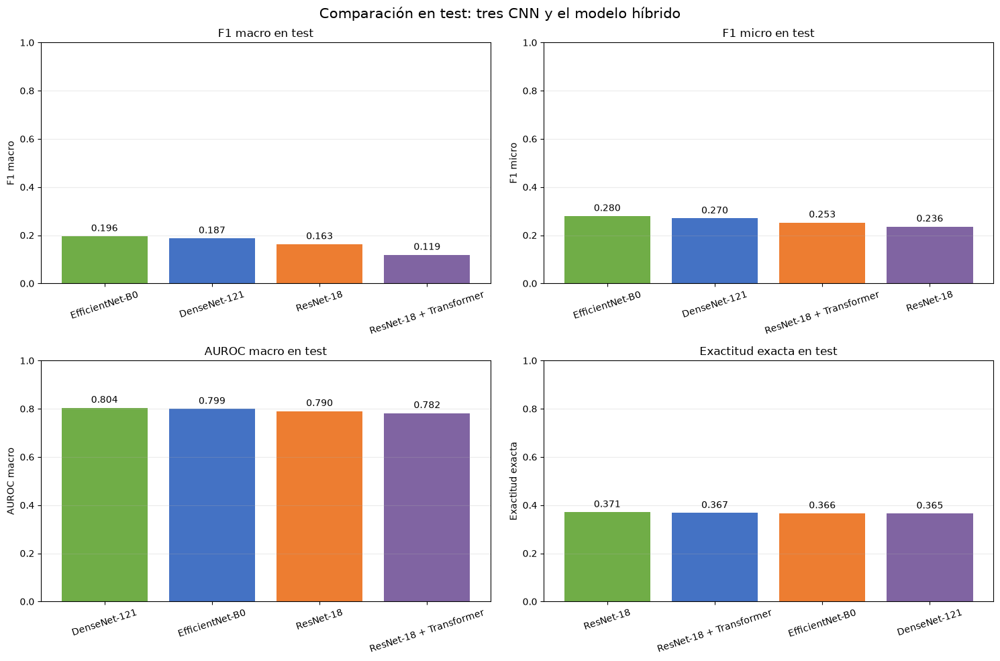

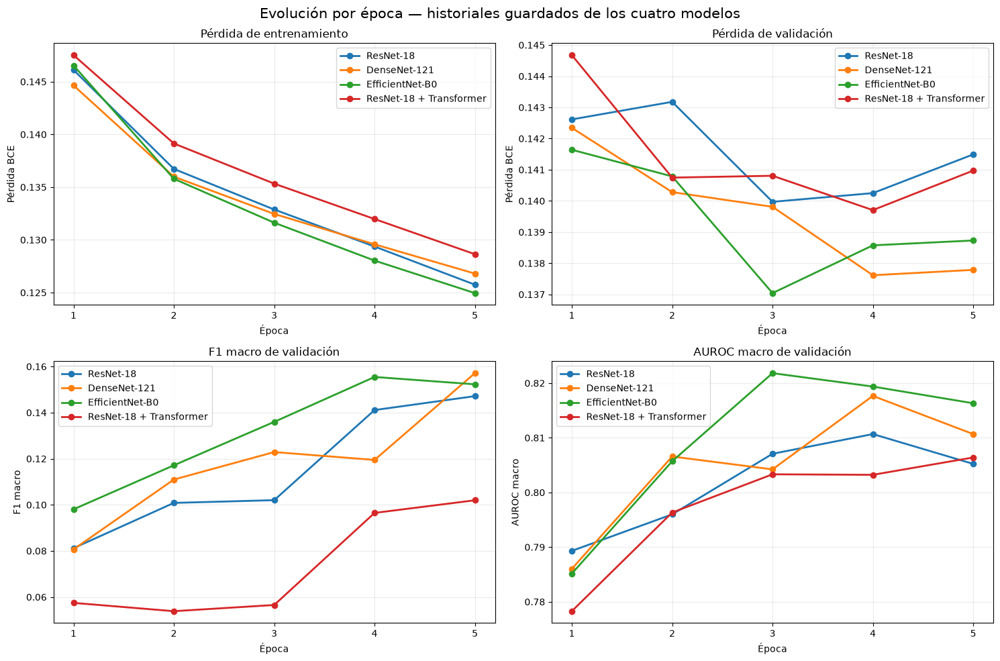

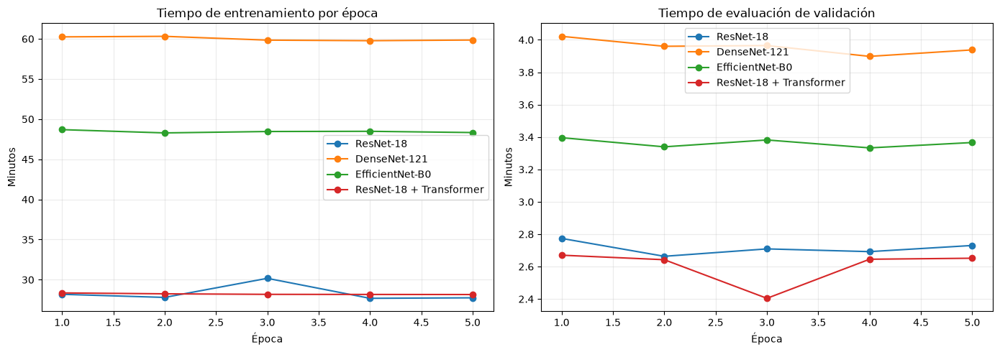

,Modelo,parámetros (millones),Mejor época guardada,tiempo train acumulado (min),evaluación test (min)
0,EfficientNet-B0,4.03,4,242.2,7.7
1,DenseNet-121,6.97,5,300.0,9.1
2,ResNet-18,11.18,5,141.6,6.3
3,ResNet-18 + Transformer,12.90,5,141.1,6.0


Todas las métricas de test usan el umbral fijo 0.5. Esta comparación solo carga resultados e historiales guardados; no reentrena ni vuelve a evaluar imágenes.


In [39]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison_output_dir = Path.cwd() / 'outputs'
base_results = pd.read_csv(comparison_output_dir / 'results.csv')
hybrid_result_path = comparison_output_dir / 'resnet18_transformer_result.csv'
hybrid_history_path = comparison_output_dir / 'resnet18_transformer_history.csv'
if not hybrid_result_path.exists() or not hybrid_history_path.exists():
    raise FileNotFoundError('Faltan los resultados o el historial guardado del modelo híbrido.')

hybrid_result = pd.read_csv(hybrid_result_path)
comparison_results = pd.concat([base_results, hybrid_result], ignore_index=True)
comparison_results = comparison_results.sort_values('test_f1_macro', ascending=False).reset_index(drop=True)
comparison_results['model'] = comparison_results['model'].replace({
    'resnet18': 'ResNet-18', 'densenet121': 'DenseNet-121',
    'efficientnet_b0': 'EfficientNet-B0', 'resnet18_transformer': 'ResNet-18 + Transformer'
})

column_names = {
    'model': 'Modelo', 'parameters': 'Parámetros', 'best_epoch': 'Mejor época',
    'best_val_f1_macro': 'F1 macro validación', 'test_loss': 'Pérdida test',
    'test_accuracy_exact': 'Exactitud exacta test', 'test_f1_macro': 'F1 macro test',
    'test_f1_micro': 'F1 micro test', 'test_auroc_macro': 'AUROC macro test',
    'test_eval_seconds': 'Evaluación test (s)'
}
display(comparison_results[list(column_names)].rename(columns=column_names).style.format({
    'F1 macro validación': '{:.3f}', 'Pérdida test': '{:.3f}',
    'Exactitud exacta test': '{:.3f}', 'F1 macro test': '{:.3f}',
    'F1 micro test': '{:.3f}', 'AUROC macro test': '{:.3f}',
    'Evaluación test (s)': '{:.1f}', 'Parámetros': '{:,.0f}'
}))

metric_panels = [
    ('test_f1_macro', 'F1 macro en test', 'F1 macro'),
    ('test_f1_micro', 'F1 micro en test', 'F1 micro'),
    ('test_auroc_macro', 'AUROC macro en test', 'AUROC macro'),
    ('test_accuracy_exact', 'Exactitud exacta en test', 'Exactitud exacta'),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
colors = ['#70AD47', '#4472C4', '#ED7D31', '#8064A2']
for ax, (metric, title, ylabel) in zip(axes.flat, metric_panels):
    ordered = comparison_results.sort_values(metric, ascending=False)
    bars = ax.bar(ordered['model'], ordered[metric], color=colors[:len(ordered)])
    ax.set(title=title, ylabel=ylabel, ylim=(0, 1))
    ax.tick_params(axis='x', rotation=18)
    ax.grid(axis='y', alpha=.25)
    ax.bar_label(bars, fmt='%.3f', padding=3)
fig.suptitle('Comparación en test: tres CNN y el modelo híbrido', fontsize=15)
fig.tight_layout()
plt.show()

comparison_histories = {
    name: pd.read_csv(comparison_output_dir / f'{filename}_history.csv')
    for name, filename in [
        ('ResNet-18', 'resnet18'), ('DenseNet-121', 'densenet121'),
        ('EfficientNet-B0', 'efficientnet_b0'),
        ('ResNet-18 + Transformer', 'resnet18_transformer')
    ]
}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
history_panels = [
    ('train_loss', 'Pérdida de entrenamiento', 'Pérdida BCE'),
    ('val_loss', 'Pérdida de validación', 'Pérdida BCE'),
    ('val_f1_macro', 'F1 macro de validación', 'F1 macro'),
    ('val_auroc_macro', 'AUROC macro de validación', 'AUROC macro'),
]
for ax, (metric, title, ylabel) in zip(axes.flat, history_panels):
    for model_name, history in comparison_histories.items():
        if metric in history.columns:
            ax.plot(history['epoch'], history[metric], marker='o', linewidth=2, label=model_name)
    ax.set(title=title, xlabel='Época', ylabel=ylabel)
    ax.set_xticks(sorted({int(e) for h in comparison_histories.values() for e in h['epoch']}))
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle('Evolución por época — historiales guardados de los cuatro modelos', fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name, history in comparison_histories.items():
    axes[0].plot(history['epoch'], history['train_seconds'] / 60, marker='o', label=model_name)
    if 'val_eval_seconds' in history:
        axes[1].plot(history['epoch'], history['val_eval_seconds'] / 60, marker='o', label=model_name)
axes[0].set(title='Tiempo de entrenamiento por época', xlabel='Época', ylabel='Minutos')
axes[1].set(title='Tiempo de evaluación de validación', xlabel='Época', ylabel='Minutos')
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend()
fig.tight_layout()
plt.show()

cost_summary = comparison_results[['model', 'parameters', 'best_epoch', 'test_eval_seconds']].copy()
cost_summary['parámetros (millones)'] = cost_summary.pop('parameters') / 1e6
cost_summary['evaluación test (min)'] = cost_summary.pop('test_eval_seconds') / 60
cost_summary = cost_summary.rename(columns={
    'model': 'Modelo', 'best_epoch': 'Mejor época guardada'
})
train_minutes_by_model = {
    model_name: history['train_seconds'].sum() / 60
    for model_name, history in comparison_histories.items()
}
cost_summary['tiempo train acumulado (min)'] = cost_summary['Modelo'].map(train_minutes_by_model)
display(cost_summary[['Modelo', 'parámetros (millones)', 'Mejor época guardada',
                      'tiempo train acumulado (min)', 'evaluación test (min)']].style.format({
    'parámetros (millones)': '{:.2f}', 'tiempo train acumulado (min)': '{:.1f}',
    'evaluación test (min)': '{:.1f}'
}))

print('Todas las métricas de test usan el umbral fijo 0.5. Esta comparación solo carga resultados e historiales guardados; no reentrena ni vuelve a evaluar imágenes.')


## 15. Ejemplos de test por radiografía: resultados de los cuatro modelos

Se presentan una a una las mismas cinco radiografías de test de la sección de ejemplos anterior. Para cada imagen se muestran sus etiquetas reales y, en filas separadas, las predicciones con umbral 0.5 y las cinco probabilidades más altas de ResNet-18, DenseNet-121, EfficientNet-B0 y ResNet-18 + Transformer. Solo se cargan los checkpoints guardados; no se reentrena.

Selección reproducible: seed 123; excluye las cinco imágenes de seed 42.
Dispositivo: mps | umbral: 0.5


/var/folders/xk/0br52t9n0mq9r4lvnbs3t_mr0000gn/T/ipykernel_16309/2498632408.py:57: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=2)


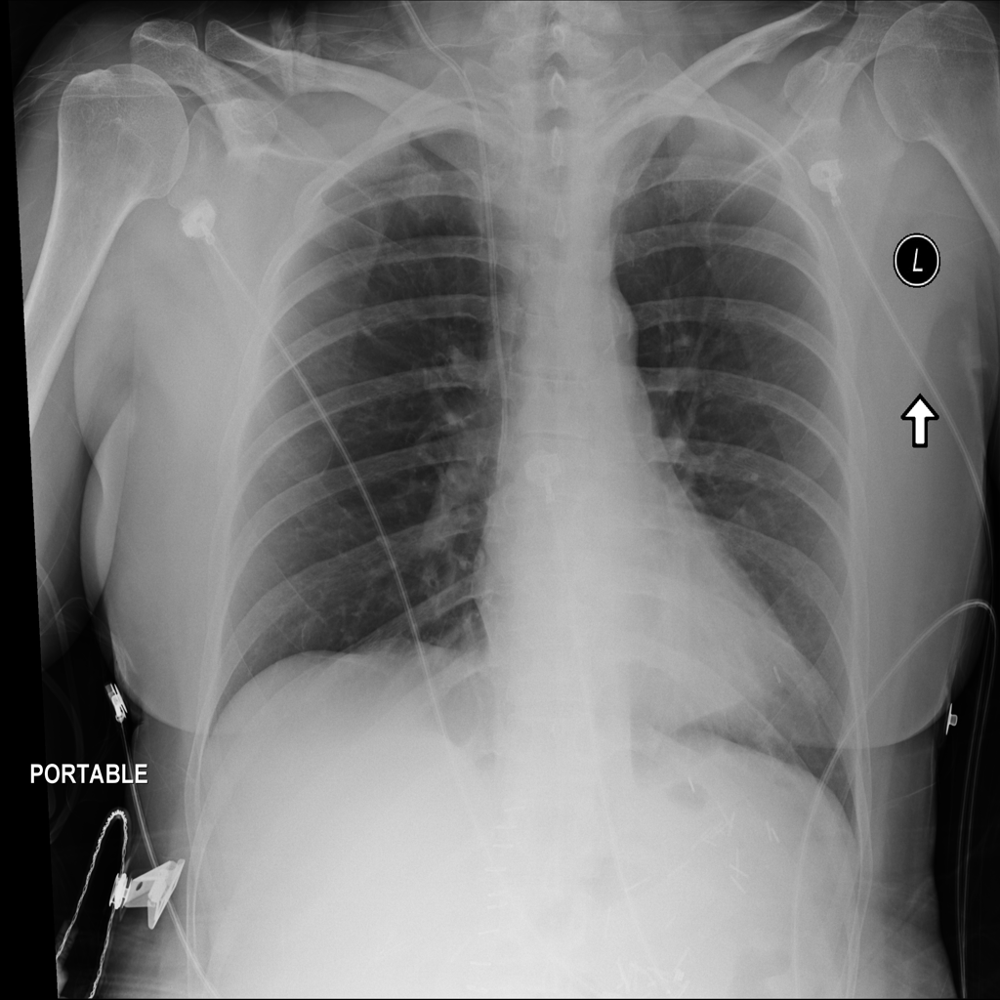

Imagen: 00020259_001.png
Etiquetas reales: ['No Finding']


,Modelo,Predicciones con umbral 0.5,Cinco probabilidades más altas
0,ResNet-18,ninguna,Infiltration: 0.073 | Atelectasis: 0.046 | Con...
1,DenseNet-121,ninguna,Infiltration: 0.089 | Atelectasis: 0.060 | Pne...
2,EfficientNet-B0,ninguna,Infiltration: 0.148 | Atelectasis: 0.112 | Pne...
3,ResNet-18 + Transformer,ninguna,Infiltration: 0.113 | Atelectasis: 0.028 | Nod...


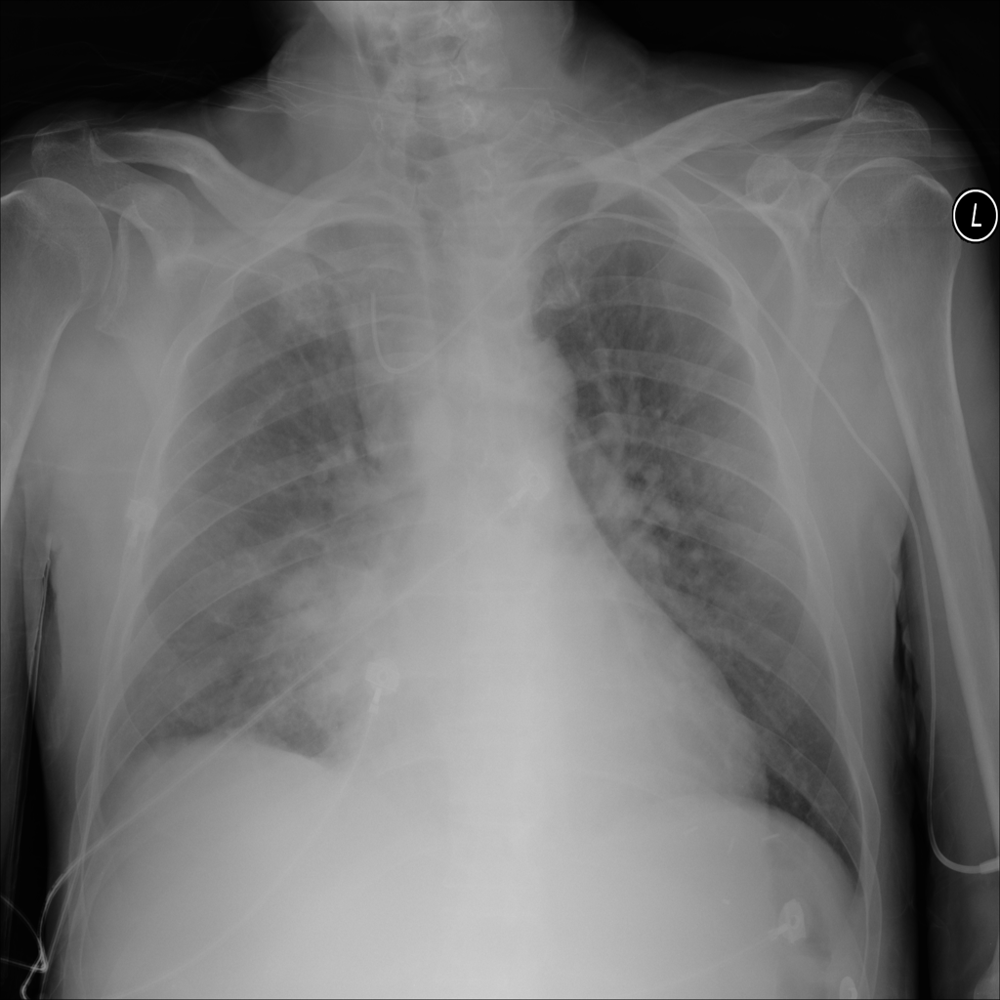

Imagen: 00020725_032.png
Etiquetas reales: ['No Finding']


,Modelo,Predicciones con umbral 0.5,Cinco probabilidades más altas
0,ResNet-18,Infiltration,Infiltration: 0.518 | Atelectasis: 0.226 | Ede...
1,DenseNet-121,ninguna,Infiltration: 0.496 | Cardiomegaly: 0.323 | Ef...
2,EfficientNet-B0,ninguna,Infiltration: 0.442 | Mass: 0.199 | Nodule: 0....
3,ResNet-18 + Transformer,Infiltration,Infiltration: 0.552 | Effusion: 0.204 | Edema:...


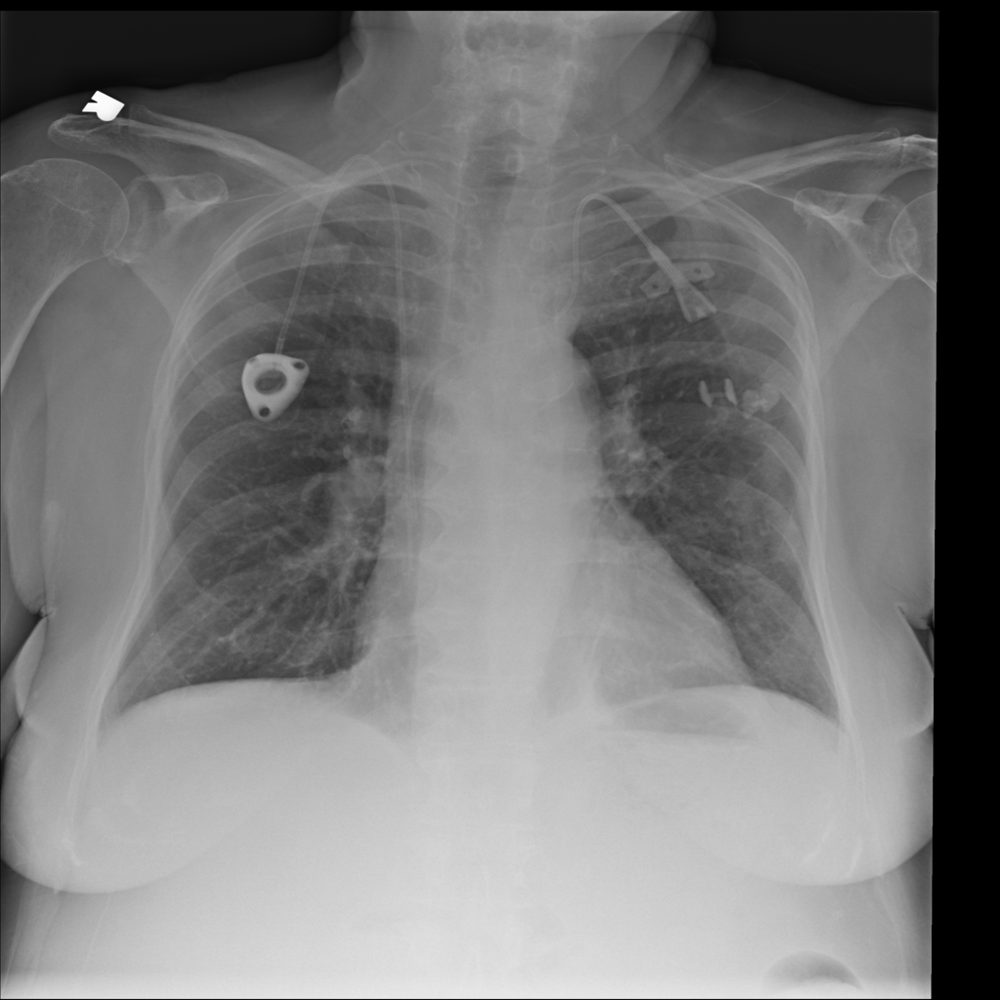

Imagen: 00026474_001.png
Etiquetas reales: ['Atelectasis', 'Infiltration']


,Modelo,Predicciones con umbral 0.5,Cinco probabilidades más altas
0,ResNet-18,ninguna,Nodule: 0.203 | Mass: 0.117 | Infiltration: 0....
1,DenseNet-121,ninguna,Effusion: 0.292 | Infiltration: 0.274 | Nodule...
2,EfficientNet-B0,ninguna,Infiltration: 0.260 | Effusion: 0.110 | Atelec...
3,ResNet-18 + Transformer,ninguna,Infiltration: 0.202 | Atelectasis: 0.083 | Eff...


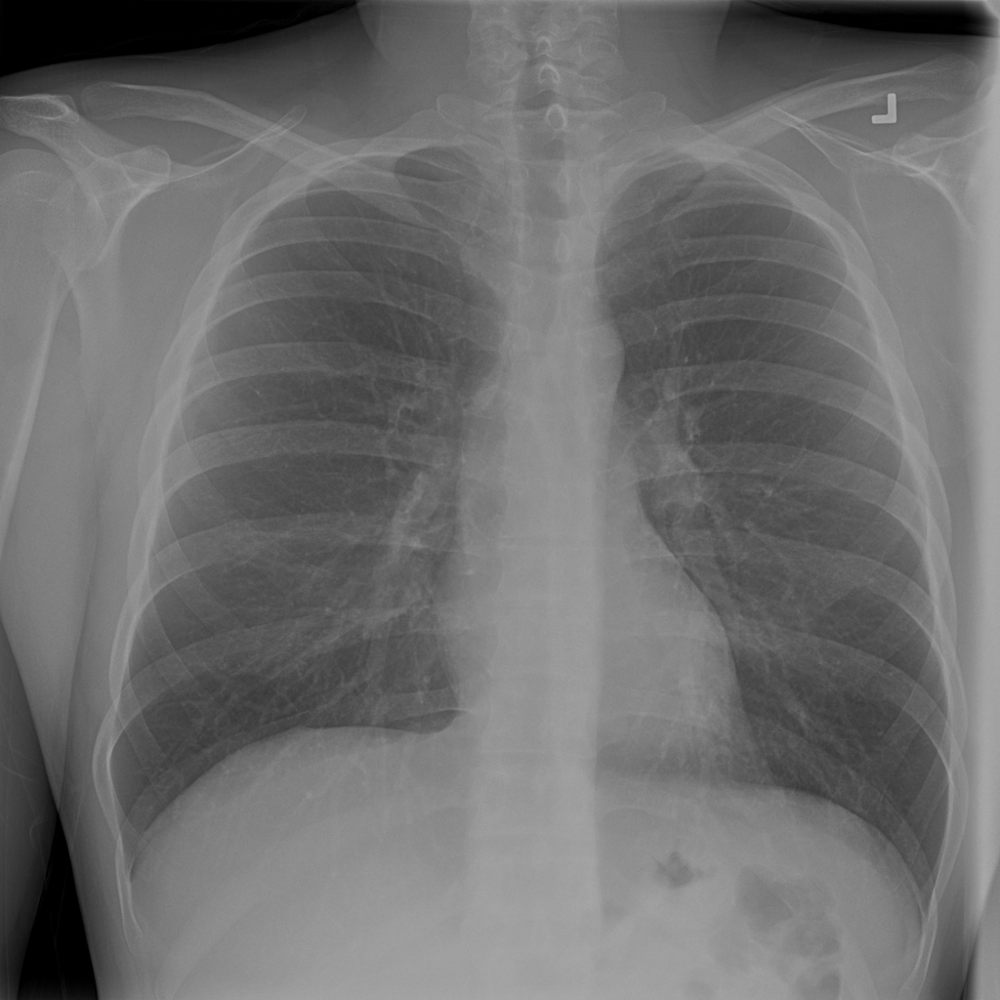

Imagen: 00028246_000.png
Etiquetas reales: ['No Finding']


,Modelo,Predicciones con umbral 0.5,Cinco probabilidades más altas
0,ResNet-18,ninguna,Infiltration: 0.270 | Nodule: 0.034 | Atelecta...
1,DenseNet-121,ninguna,Infiltration: 0.497 | Pleural_Thickening: 0.01...
2,EfficientNet-B0,ninguna,Infiltration: 0.389 | Nodule: 0.008 | Atelecta...
3,ResNet-18 + Transformer,ninguna,Infiltration: 0.408 | Nodule: 0.035 | Consolid...


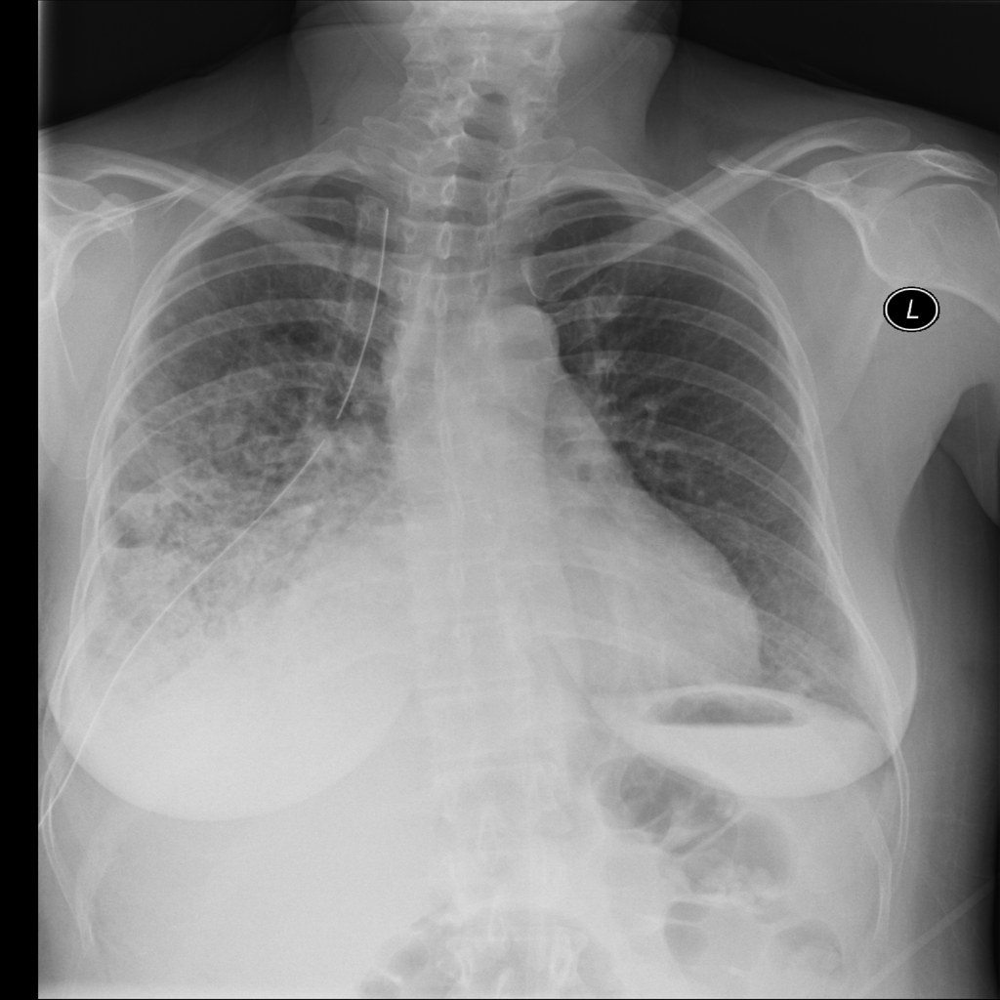

Imagen: 00013391_005.png
Etiquetas reales: ['Infiltration', 'Pneumonia']


,Modelo,Predicciones con umbral 0.5,Cinco probabilidades más altas
0,ResNet-18,Effusion,Effusion: 0.540 | Infiltration: 0.445 | Cardio...
1,DenseNet-121,Effusion,Effusion: 0.620 | Infiltration: 0.495 | Cardio...
2,EfficientNet-B0,Effusion | Infiltration,Effusion: 0.664 | Infiltration: 0.616 | Atelec...
3,ResNet-18 + Transformer,Effusion,Effusion: 0.572 | Infiltration: 0.493 | Pleura...


In [40]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image
from IPython.display import display

examples_output_dir = Path.cwd() / 'outputs'
examples_data_root = Path.cwd() / 'Data'
examples_manifest = pd.read_csv(examples_output_dir / 'split_manifest.csv')
example_labels = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
    'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# Reutiliza exactamente la selección de cinco imágenes de la sección previa.
examples_test = examples_manifest[examples_manifest['split'] == 'test']
previous_five = examples_test.sample(n=5, random_state=42)
examples_remaining = examples_test[~examples_test['Image Index'].isin(previous_five['Image Index'])]
five_test_rows = examples_remaining.sample(n=5, random_state=123).reset_index(drop=True)

examples_device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
examples_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize((.485, .456, .406), (.229, .224, .225))
])

def build_saved_model(name):
    if name == 'resnet18':
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, len(example_labels))
    elif name == 'densenet121':
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, len(example_labels))
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(example_labels))
    elif name == 'resnet18_transformer':
        class ResNet18TransformerForExamples(nn.Module):
            def __init__(self):
                super().__init__()
                backbone = models.resnet18(weights=None)
                self.cnn = nn.Sequential(
                    backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
                    backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4
                )
                self.projection = nn.Conv2d(512, 256, kernel_size=1)
                self.cls_token = nn.Parameter(torch.zeros(1, 1, 256))
                self.position_embedding = nn.Parameter(torch.zeros(1, 50, 256))
                layer = nn.TransformerEncoderLayer(
                    d_model=256, nhead=4, dim_feedforward=1024,
                    dropout=0.1, batch_first=True, norm_first=True
                )
                self.transformer = nn.TransformerEncoder(layer, num_layers=2)
                self.classifier = nn.Linear(256, len(example_labels))

            def forward(self, x):
                features = self.cnn(x)
                tokens = self.projection(features).flatten(2).transpose(1, 2)
                cls = self.cls_token.expand(tokens.shape[0], -1, -1)
                tokens = torch.cat([cls, tokens], dim=1)
                encoded = self.transformer(tokens + self.position_embedding)
                return self.classifier(encoded[:, 0])
        model = ResNet18TransformerForExamples()
    else:
        raise ValueError(f'Modelo desconocido: {name}')

    checkpoint = torch.load(
        examples_output_dir / f'{name}_best.pt', map_location='cpu', weights_only=False
    )
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(examples_device).eval()

example_models = {
    'ResNet-18': build_saved_model('resnet18'),
    'DenseNet-121': build_saved_model('densenet121'),
    'EfficientNet-B0': build_saved_model('efficientnet_b0'),
    'ResNet-18 + Transformer': build_saved_model('resnet18_transformer'),
}

print('Selección reproducible: seed 123; excluye las cinco imágenes de seed 42.')
print('Dispositivo:', examples_device, '| umbral:', 0.5)
for _, image_row in five_test_rows.iterrows():
    image_name = image_row['Image Index']
    image_path = Path(image_row['ImagePath'])
    if not image_path.exists():
        matches = list(examples_data_root.rglob(image_name))
        if not matches:
            raise FileNotFoundError(f'No se encontró {image_name} bajo {examples_data_root}')
        image_path = matches[0]

    with Image.open(image_path) as source_image:
        image = source_image.convert('RGB')
        display(image)
        image_tensor = examples_transform(image).unsqueeze(0).to(examples_device)

    real_labels = [label for label in example_labels if int(image_row[label]) == 1]
    result_rows = []
    with torch.inference_mode():
        for model_name, model in example_models.items():
            probabilities = torch.sigmoid(model(image_tensor))[0].cpu().numpy()
            predictions = [label for label, score in zip(example_labels, probabilities) if score >= 0.5]
            top_indices = np.argsort(probabilities)[::-1][:5]
            top_text = ' | '.join(f'{example_labels[i]}: {probabilities[i]:.3f}' for i in top_indices)
            result_rows.append({
                'Modelo': model_name,
                'Predicciones con umbral 0.5': ' | '.join(predictions) if predictions else 'ninguna',
                'Cinco probabilidades más altas': top_text,
            })

    print(f'Imagen: {image_name}')
    print(f'Etiquetas reales: {real_labels or ["No Finding"]}')
    display(pd.DataFrame(result_rows))
    print()
    del image_tensor
    if examples_device.type == 'mps':
        torch.mps.empty_cache()
del example_models


## 16. Auditoría final sin reentrenamiento

Esta sección aprovecha artefactos existentes. Resume convergencia y desbalance, documenta el entorno y mide memoria de inferencia con batch 1. No ajusta umbrales, no reentrena, no modifica pesos y no escribe archivos de resultados. La memoria histórica de entrenamiento no se registró, por lo que no puede reconstruirse retrospectivamente.

In [41]:
from pathlib import Path
import json
import platform
import sys
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image
from IPython.display import display, Markdown

audit_output_dir = Path.cwd() / 'outputs'
audit_data_root = Path.cwd() / 'Data'
audit_labels = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
    'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]
audit_names = {
    'resnet18': 'ResNet-18', 'densenet121': 'DenseNet-121',
    'efficientnet_b0': 'EfficientNet-B0',
    'resnet18_transformer': 'ResNet-18 + Transformer'
}
audit_histories = {
    name: pd.read_csv(audit_output_dir / f'{name}_history.csv')
    for name in audit_names
}

# 1) Evidencia de convergencia en los historiales guardados (sin reentrenar).
convergence_rows = []
for model_key, history in audit_histories.items():
    history = history.sort_values('epoch').reset_index(drop=True)
    best = history.loc[history['val_f1_macro'].idxmax()]
    last = history.iloc[-1]
    first_loss, last_loss = history.iloc[0]['train_loss'], last['train_loss']
    convergence_rows.append({
        'Modelo': audit_names[model_key],
        'Épocas guardadas': int(history['epoch'].max()),
        'Mejor época (F1 validación)': int(best['epoch']),
        'Mejor F1 macro validación': best['val_f1_macro'],
        'F1 macro última época': last['val_f1_macro'],
        'Reducción pérdida train (%)': 100 * (first_loss - last_loss) / first_loss,
        'Mejor F1 en última época': bool(best['epoch'] == last['epoch']),
    })
display(pd.DataFrame(convergence_rows).style.format({
    'Mejor F1 macro validación': '{:.3f}', 'F1 macro última época': '{:.3f}',
    'Reducción pérdida train (%)': '{:.1f}%'
}))
print('Lectura: si la mejor época coincide con la última, estos historiales no demuestran que se alcanzó una meseta.')

# 2) Cuantifica el desbalance y deja pos_weight como diagnóstico, no como cambio retroactivo.
audit_manifest = pd.read_csv(audit_output_dir / 'split_manifest.csv')
audit_train = audit_manifest[audit_manifest['split'] == 'train']
positive = audit_train[audit_labels].sum().astype(int)
negative = len(audit_train) - positive
imbalance_audit = pd.DataFrame({
    'Positivos train': positive,
    'Negativos train': negative,
    'Prevalencia (%)': 100 * positive / len(audit_train),
    'Razón neg/pos': negative / positive.replace(0, np.nan),
    'pos_weight sugerido': negative / positive.replace(0, np.nan),
}).sort_values('Prevalencia (%)')
display(imbalance_audit.style.format({
    'Prevalencia (%)': '{:.2f}%', 'Razón neg/pos': '{:.1f}:1',
    'pos_weight sugerido': '{:.1f}'
}))
print('pos_weight es solo una propuesta para un experimento futuro; no se aplicó a los checkpoints existentes.')

# 3) Registra el entorno conocido desde los archivos de configuración y runtime actual.
base_config = json.loads((audit_output_dir / 'run_config.json').read_text(encoding='utf-8'))
hybrid_config = json.loads((audit_output_dir / 'resnet18_transformer_run_config.json').read_text(encoding='utf-8'))
environment_summary = pd.DataFrame([
    {'Configuración': 'Tres modelos base', **base_config},
    {'Configuración': 'CNN + Transformer', **hybrid_config},
])
display(environment_summary)
print('Runtime actual — Python:', sys.version.split()[0], '| PyTorch:', torch.__version__,
      '| máquina:', platform.machine(), '| macOS:', platform.mac_ver()[0] or 'no disponible')

# 4) Perfil de memoria de INFERENCIA con un ejemplo y batch=1. No estima el pico histórico de entrenamiento.
audit_device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print('Dispositivo para perfil de inferencia:', audit_device)

def make_audit_model(name):
    if name == 'resnet18':
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, len(audit_labels))
    elif name == 'densenet121':
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, len(audit_labels))
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(audit_labels))
    elif name == 'resnet18_transformer':
        class AuditHybrid(nn.Module):
            def __init__(self):
                super().__init__()
                backbone = models.resnet18(weights=None)
                self.cnn = nn.Sequential(
                    backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
                    backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4
                )
                self.projection = nn.Conv2d(512, 256, kernel_size=1)
                self.cls_token = nn.Parameter(torch.zeros(1, 1, 256))
                self.position_embedding = nn.Parameter(torch.zeros(1, 50, 256))
                layer = nn.TransformerEncoderLayer(
                    d_model=256, nhead=4, dim_feedforward=1024,
                    dropout=0.1, batch_first=True, norm_first=True
                )
                self.transformer = nn.TransformerEncoder(layer, num_layers=2)
                self.classifier = nn.Linear(256, len(audit_labels))
            def forward(self, x):
                tokens = self.projection(self.cnn(x)).flatten(2).transpose(1, 2)
                cls = self.cls_token.expand(tokens.shape[0], -1, -1)
                encoded = self.transformer(torch.cat([cls, tokens], dim=1) + self.position_embedding)
                return self.classifier(encoded[:, 0])
        model = AuditHybrid()
    else:
        raise ValueError(name)
    checkpoint = torch.load(audit_output_dir / f'{name}_best.pt', map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(audit_device).eval()

def mps_memory_mib():
    if audit_device.type != 'mps':
        return {'tensor_mib': np.nan, 'metal_driver_mib': np.nan}
    torch.mps.synchronize()
    tensor_mib = torch.mps.current_allocated_memory() / (1024 ** 2)
    driver_mib = torch.mps.driver_allocated_memory() / (1024 ** 2)
    return {'tensor_mib': tensor_mib, 'metal_driver_mib': driver_mib}

audit_rows = audit_manifest[audit_manifest['split'] == 'test']
first_seed42 = audit_rows.sample(n=5, random_state=42)
seed123_row = (audit_rows[~audit_rows['Image Index'].isin(first_seed42['Image Index'])]
               .sample(n=5, random_state=123).iloc[0])
audit_image_path = Path(seed123_row['ImagePath'])
if not audit_image_path.exists():
    audit_image_path = next(audit_data_root.rglob(seed123_row['Image Index']))
with Image.open(audit_image_path) as im:
    audit_x = transforms.Compose([
        transforms.Resize((224, 224)), transforms.ToTensor(),
        transforms.Normalize((.485, .456, .406), (.229, .224, .225))
    ])(im.convert('RGB')).unsqueeze(0).to(audit_device)
print('Radiografía usada para perfil de inferencia:', seed123_row['Image Index'], '(batch=1, 224×224)')

memory_rows = []
if audit_device.type == 'mps' and not hasattr(torch.mps, 'driver_allocated_memory'):
    print('Esta versión de PyTorch no expone driver_allocated_memory; se omite el perfil MPS.')
else:
    for model_key, model_label in audit_names.items():
        if audit_device.type == 'mps':
            torch.mps.empty_cache()
        before = mps_memory_mib()
        audit_model = make_audit_model(model_key)
        loaded = mps_memory_mib()
        with torch.inference_mode():
            _ = audit_model(audit_x)
        after = mps_memory_mib()
        memory_rows.append({
            'Modelo': model_label,
            'Tensores tras cargar (MiB)': loaded['tensor_mib'],
            'Tensores tras inferencia (MiB)': after['tensor_mib'],
            'Metal driver tras inferencia (MiB)': after['metal_driver_mib'],
            'Δ driver vs. antes de cargar (MiB)': after['metal_driver_mib'] - before['metal_driver_mib'],
        })
        del audit_model
        if audit_device.type == 'mps':
            torch.mps.synchronize()
            torch.mps.empty_cache()
    if memory_rows:
        display(pd.DataFrame(memory_rows).style.format({
            'Tensores tras cargar (MiB)': '{:.1f}',
            'Tensores tras inferencia (MiB)': '{:.1f}',
            'Metal driver tras inferencia (MiB)': '{:.1f}',
            'Δ driver vs. antes de cargar (MiB)': '{:.1f}',
        }))
    elif audit_device.type != 'mps':
        print('El perfil de memoria disponible aquí solo se habilitó para MPS; no se informa un dato de CPU como memoria de GPU.')

print('Alcance: estas lecturas son memoria de inferencia de una imagen, no memoria pico de entrenamiento. La memoria histórica de entrenamiento no quedó registrada y no se puede recuperar sin repetir la ejecución instrumentada.')
print('Este bloque no modifica pesos ni archivos de outputs; solo lee configuraciones, historiales, manifiesto y checkpoints.')


,Modelo,Épocas guardadas,Mejor época (F1 validación),Mejor F1 macro validación,F1 macro última época,Reducción pérdida train (%),Mejor F1 en última época
0,ResNet-18,5,5,0.147,0.147,13.9%,True
1,DenseNet-121,5,5,0.157,0.157,12.3%,True
2,EfficientNet-B0,5,4,0.155,0.152,14.7%,False
3,ResNet-18 + Transformer,5,5,0.102,0.102,12.8%,True


Lectura: si la mejor época coincide con la última, estos historiales no demuestran que se alcanzó una meseta.


,Positivos train,Negativos train,Prevalencia (%),Razón neg/pos,pos_weight sugerido
Hernia,123,75433,0.16%,613.3:1,613.3
Pneumonia,758,74798,1.00%,98.7:1,98.7
Fibrosis,1105,74451,1.46%,67.4:1,67.4
Edema,1204,74352,1.59%,61.8:1,61.8
Emphysema,1267,74289,1.68%,58.6:1,58.6
Cardiomegaly,1498,74058,1.98%,49.4:1,49.4
Pleural_Thickening,1973,73583,2.61%,37.3:1,37.3
Pneumothorax,2254,73302,2.98%,32.5:1,32.5
Consolidation,2489,73067,3.29%,29.4:1,29.4
Mass,3499,72057,4.63%,20.6:1,20.6


pos_weight es solo una propuesta para un experimento futuro; no se aplicó a los checkpoints existentes.


,Configuración,seed,image_size,batch_size,epochs,max_images,models,device,optimizer,learning_rate,weight_decay,loss,threshold,selection_metric,architecture
0,Tres modelos base,42,224,8,5,NaN,"[resnet18, densenet121, efficientnet_b0]",mps,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CNN + Transformer,42,224,8,5,NaN,NaN,mps,AdamW,0.0001,0.0001,BCEWithLogitsLoss,0.5,validation macro F1,ResNet-18 feature map + 2-layer TransformerEnc...


Runtime actual — Python: 3.14.7 | PyTorch: 2.13.0 | máquina: arm64 | macOS: 27.0.1
Dispositivo para perfil de inferencia: mps
Radiografía usada para perfil de inferencia: 00020259_001.png (batch=1, 224×224)


/var/folders/xk/0br52t9n0mq9r4lvnbs3t_mr0000gn/T/ipykernel_34416/2464675199.py:111: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=2)


,Modelo,Tensores tras cargar (MiB),Tensores tras inferencia (MiB),Metal driver tras inferencia (MiB),Δ driver vs. antes de cargar (MiB)
0,ResNet-18,43.3,43.3,84.9,76.5
1,DenseNet-121,27.5,27.5,88.7,68.0
2,EfficientNet-B0,16.1,16.1,70.2,47.5
3,ResNet-18 + Transformer,49.8,49.8,92.9,64.3


Alcance: estas lecturas son memoria de inferencia de una imagen, no memoria pico de entrenamiento. La memoria histórica de entrenamiento no quedó registrada y no se puede recuperar sin repetir la ejecución instrumentada.
Este bloque no modifica pesos ni archivos de outputs; solo lee configuraciones, historiales, manifiesto y checkpoints.
